# 2 signals hypothesis:

- **`g` — goal-directedness direction**: A linear direction (possibly encoded by a sparse set of attention heads) encoding *which* instrumental goal is currently being pursued. In our setting: which predicate the model is about to implement. 
  * Expected Properties:
    - Context-stable: same for different contexts, e.g. programming languages, docstring, arg names, ...
    - Plastic: general direction, doesn't matter how the LM chooses to implement it.

- **`c` — goal-completion signal**: A representation tracking *progress* toward the current goal. Stages might include:
  - Has the goal been started yet?
  - Is the model mid-implementation?
  - Is the goal complete?
  - Should the model transition to the next instrumental goal?

Think of it as a simple state machine. `g` is the state label; `c` is the **clock** that drives transitions.

In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("..")

In [2]:
import os
import sys

sys.path.append("../")

##################################################################
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["CUDA_VISIBLE_DEVICES"] = "0,1,2,3,4,5"
##################################################################

import logging
import torch
import transformers

from rich.console import Console
from rich.theme import Theme

from src.utils import logging_utils
from src.utils import env_utils
import seaborn as sns

custom_theme = Theme({"default": "white"})
console = Console(theme=custom_theme)


def rich_print(*args, **kwargs):
    console.print(*args, **kwargs)


logger = logging.getLogger(__name__)

logging.basicConfig(
    level=logging.DEBUG,
    format=logging_utils.DEFAULT_FORMAT,
    datefmt=logging_utils.DEFAULT_DATEFMT,
    stream=sys.stdout,
)

logger.info(f"{torch.__version__=}, {torch.version.cuda=}")
logger.info(
    f"{torch.cuda.is_available()=}, {torch.cuda.device_count()=}, {torch.cuda.get_device_name()=}"
)
logger.info(f"{transformers.__version__=}")

2026-04-02 17:18:15 __main__ INFO     torch.__version__='2.6.0+cu124', torch.version.cuda='12.4'
2026-04-02 17:18:16 __main__ INFO     torch.cuda.is_available()=True, torch.cuda.device_count()=6, torch.cuda.get_device_name()='NVIDIA A100-SXM4-80GB'
2026-04-02 17:18:16 __main__ INFO     transformers.__version__='5.3.0'


In [3]:
from src.models import ModelandTokenizer

MODEL_NAME = "Qwen/Qwen2.5-Coder-32B-Instruct"
# MODEL_NAME = "meta-llama/Llama-3.3-70B-Instruct"

mt = ModelandTokenizer(
    model_key=MODEL_NAME,
    dtype=torch.bfloat16,
    device_map="auto",
    attn_implementation="eager",
)
print(f"n_layer={mt.n_layer}, n_embd={mt.n_embd}, n_heads={mt.model.config.num_attention_heads}")
print(f"head_dim={mt.n_embd // mt.model.config.num_attention_heads}")
print(f"attn_module_name_format={mt.attn_module_name_format!r}")

2026-04-02 17:18:17 src.models WARNING  Qwen/Qwen2.5-Coder-32B-Instruct not found in /disk/u/arnab/Codes/Models
If not found in cache, model will be downloaded from HuggingFace to cache directory
2026-04-02 17:18:17 httpx DEBUG    load_ssl_context verify=True cert=None trust_env=True http2=False
2026-04-02 17:18:17 httpx DEBUG    load_verify_locations cafile='/disk/u/arnab/miniconda3/envs/goals/lib/python3.11/site-packages/certifi/cacert.pem'
2026-04-02 17:18:17 httpcore.connection DEBUG    connect_tcp.started host='huggingface.co' port=443 local_address=None timeout=10 socket_options=None
2026-04-02 17:18:17 httpcore.connection DEBUG    connect_tcp.complete return_value=<httpcore._backends.sync.SyncStream object at 0x7fe556863a90>
2026-04-02 17:18:17 httpcore.connection DEBUG    start_tls.started ssl_context=<ssl.SSLContext object at 0x7fe556a0d7f0> server_hostname='huggingface.co' timeout=10
2026-04-02 17:18:17 httpcore.connection DEBUG    start_tls.complete return_value=<httpcore._b

Loading weights:   0%|          | 0/771 [00:00<?, ?it/s]

2026-04-02 17:18:33 httpcore.connection DEBUG    close.started
2026-04-02 17:18:33 httpcore.connection DEBUG    close.complete
2026-04-02 17:18:33 httpcore.connection DEBUG    connect_tcp.started host='huggingface.co' port=443 local_address=None timeout=10 socket_options=None
2026-04-02 17:18:33 httpcore.connection DEBUG    connect_tcp.complete return_value=<httpcore._backends.sync.SyncStream object at 0x7fe55721d0d0>
2026-04-02 17:18:33 httpcore.connection DEBUG    start_tls.started ssl_context=<ssl.SSLContext object at 0x7fe556a0d7f0> server_hostname='huggingface.co' timeout=10
2026-04-02 17:18:33 httpcore.connection DEBUG    start_tls.complete return_value=<httpcore._backends.sync.SyncStream object at 0x7fe554b7e290>
2026-04-02 17:18:33 httpcore.http11 DEBUG    send_request_headers.started request=<Request [b'HEAD']>
2026-04-02 17:18:33 httpcore.http11 DEBUG    send_request_headers.complete
2026-04-02 17:18:33 httpcore.http11 DEBUG    send_request_body.started request=<Request [b'HE

## Loading selected attention heads

In [4]:
import os
import torch
from src.goals.head_loc_attn import HeadMask

MASK_PATH = os.path.join(
    env_utils.DEFAULT_RESULTS_DIR,
    f"localization/{MODEL_NAME.split('/')[-1]}/lam20/head_mask.pt",
)

ckpt = torch.load(MASK_PATH, map_location="cpu")
print(f"Loaded checkpoint from {MASK_PATH}")
# print(f"  Trained for {ckpt['config']['n_epochs']} epochs  |  N={ckpt['config']['n_instances']} instances")
# print(f"  λ_sparse={ckpt['config']['lambda_sparse']}  lr={ckpt['config']['lr']}")

# Reconstruct mask object
LAYERS = ckpt["layers"]
n_layers_tested = len(LAYERS)
n_heads = ckpt["mask_values"].shape[1]
mask = HeadMask(n_layers_tested, n_heads)
with torch.no_grad():
    mask.values.copy_(ckpt["mask_values"])
    if mt.name.split("/")[-1] == "Qwen2.5-Coder-32B-Instruct":
        mask.values[0:25] = 0  # zero out early layers
        mask.values[56:] = 0  # zero out late layers
    if mt.name.split("/")[-1] == "Llama-3.3-70B-Instruct":
        mask.values[0:18] = 0  # zero out early layers
        mask.values[45:] = 0  # zero out late layers

threshold = 0.9
selected_heads = mask.selected_heads(LAYERS, threshold=threshold)
print(
    f"\n  Layers: {LAYERS[0]}–{LAYERS[-1]}  ({n_layers_tested} tested, {n_heads} heads each)"
)
print(f"  Active heads (mask > {threshold}): {len(selected_heads)}")
print(f"  Selected heads: {selected_heads}")

Loaded checkpoint from /disk/u/arnab/Codes/Projects/goals/results/localization/Qwen2.5-Coder-32B-Instruct/head_mask.pt

  Layers: 0–63  (64 tested, 40 heads each)
  Active heads (mask > 0.9): 122
  Selected heads: [(28, 13), (29, 17), (29, 18), (30, 8), (30, 25), (30, 35), (31, 18), (31, 32), (32, 3), (32, 13), (34, 25), (34, 30), (34, 33), (35, 13), (35, 39), (37, 13), (37, 15), (38, 0), (38, 2), (39, 4), (39, 8), (39, 9), (39, 14), (39, 31), (39, 32), (39, 34), (40, 2), (40, 8), (40, 11), (40, 14), (40, 32), (40, 34), (41, 6), (41, 9), (41, 12), (41, 13), (42, 39), (43, 5), (43, 8), (43, 13), (43, 30), (44, 12), (44, 13), (44, 14), (44, 18), (44, 38), (45, 15), (45, 17), (45, 18), (45, 21), (45, 22), (45, 31), (45, 32), (45, 33), (45, 34), (46, 1), (46, 4), (46, 7), (46, 8), (46, 9), (46, 18), (46, 19), (46, 20), (46, 25), (46, 26), (46, 35), (47, 5), (47, 6), (47, 7), (47, 8), (47, 18), (47, 19), (47, 23), (47, 30), (47, 32), (47, 35), (47, 39), (48, 25), (48, 26), (48, 28), (48, 29

2026-04-01 17:01:06 matplotlib.pyplot DEBUG    Loaded backend module://matplotlib_inline.backend_inline version unknown.
2026-04-01 17:01:06 matplotlib.pyplot DEBUG    Loaded backend module://matplotlib_inline.backend_inline version unknown.
2026-04-01 17:01:06 matplotlib.font_manager DEBUG    findfont: Matching sans\-serif:style=normal:variant=normal:weight=normal:stretch=normal:size=10.0.
2026-04-01 17:01:06 matplotlib.font_manager DEBUG    findfont: score(FontEntry(fname='/disk/u/arnab/miniconda3/envs/goals/lib/python3.11/site-packages/matplotlib/mpl-data/fonts/ttf/cmsy10.ttf', name='cmsy10', style='normal', variant='normal', weight=400, stretch='normal', size='scalable')) = 10.05
2026-04-01 17:01:06 matplotlib.font_manager DEBUG    findfont: score(FontEntry(fname='/disk/u/arnab/miniconda3/envs/goals/lib/python3.11/site-packages/matplotlib/mpl-data/fonts/ttf/STIXSizThreeSymReg.ttf', name='STIXSizeThreeSym', style='normal', variant='normal', weight=400, stretch='normal', size='scalab

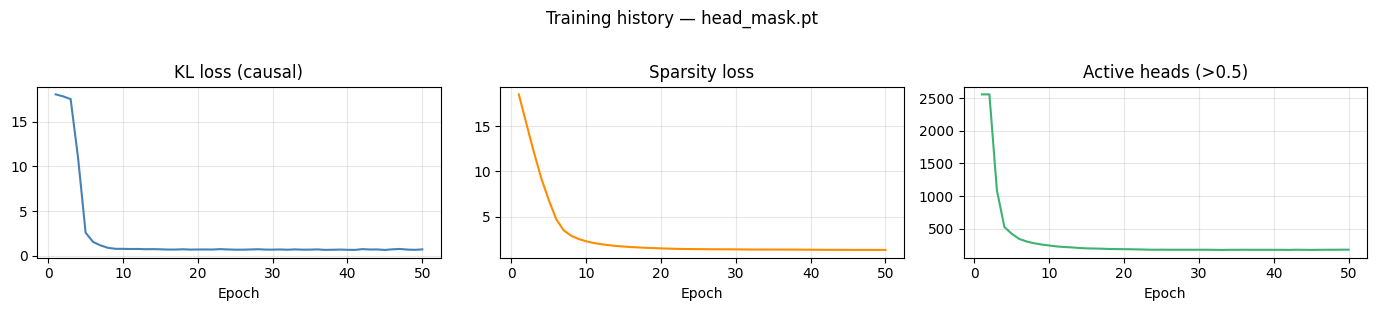

In [5]:
# Training curves from the checkpoint
from matplotlib import pyplot as plt
import numpy as np

plt.rcdefaults()

h = ckpt["history"]
xs = np.arange(1, len(h["loss_total"]) + 1)

fig, axes = plt.subplots(1, 3, figsize=(14, 3))
axes[0].plot(xs, h["loss_causal"],  color="steelblue");  axes[0].set_title("KL loss (causal)")
axes[1].plot(xs, h["loss_sparse"],  color="darkorange"); axes[1].set_title("Sparsity loss")
axes[2].plot(xs, h["n_active"],     color="mediumseagreen"); axes[2].set_title("Active heads (>0.5)")
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.3)
plt.suptitle(f"Training history — {os.path.basename(MASK_PATH)}", y=1.02)
plt.tight_layout()
plt.show()

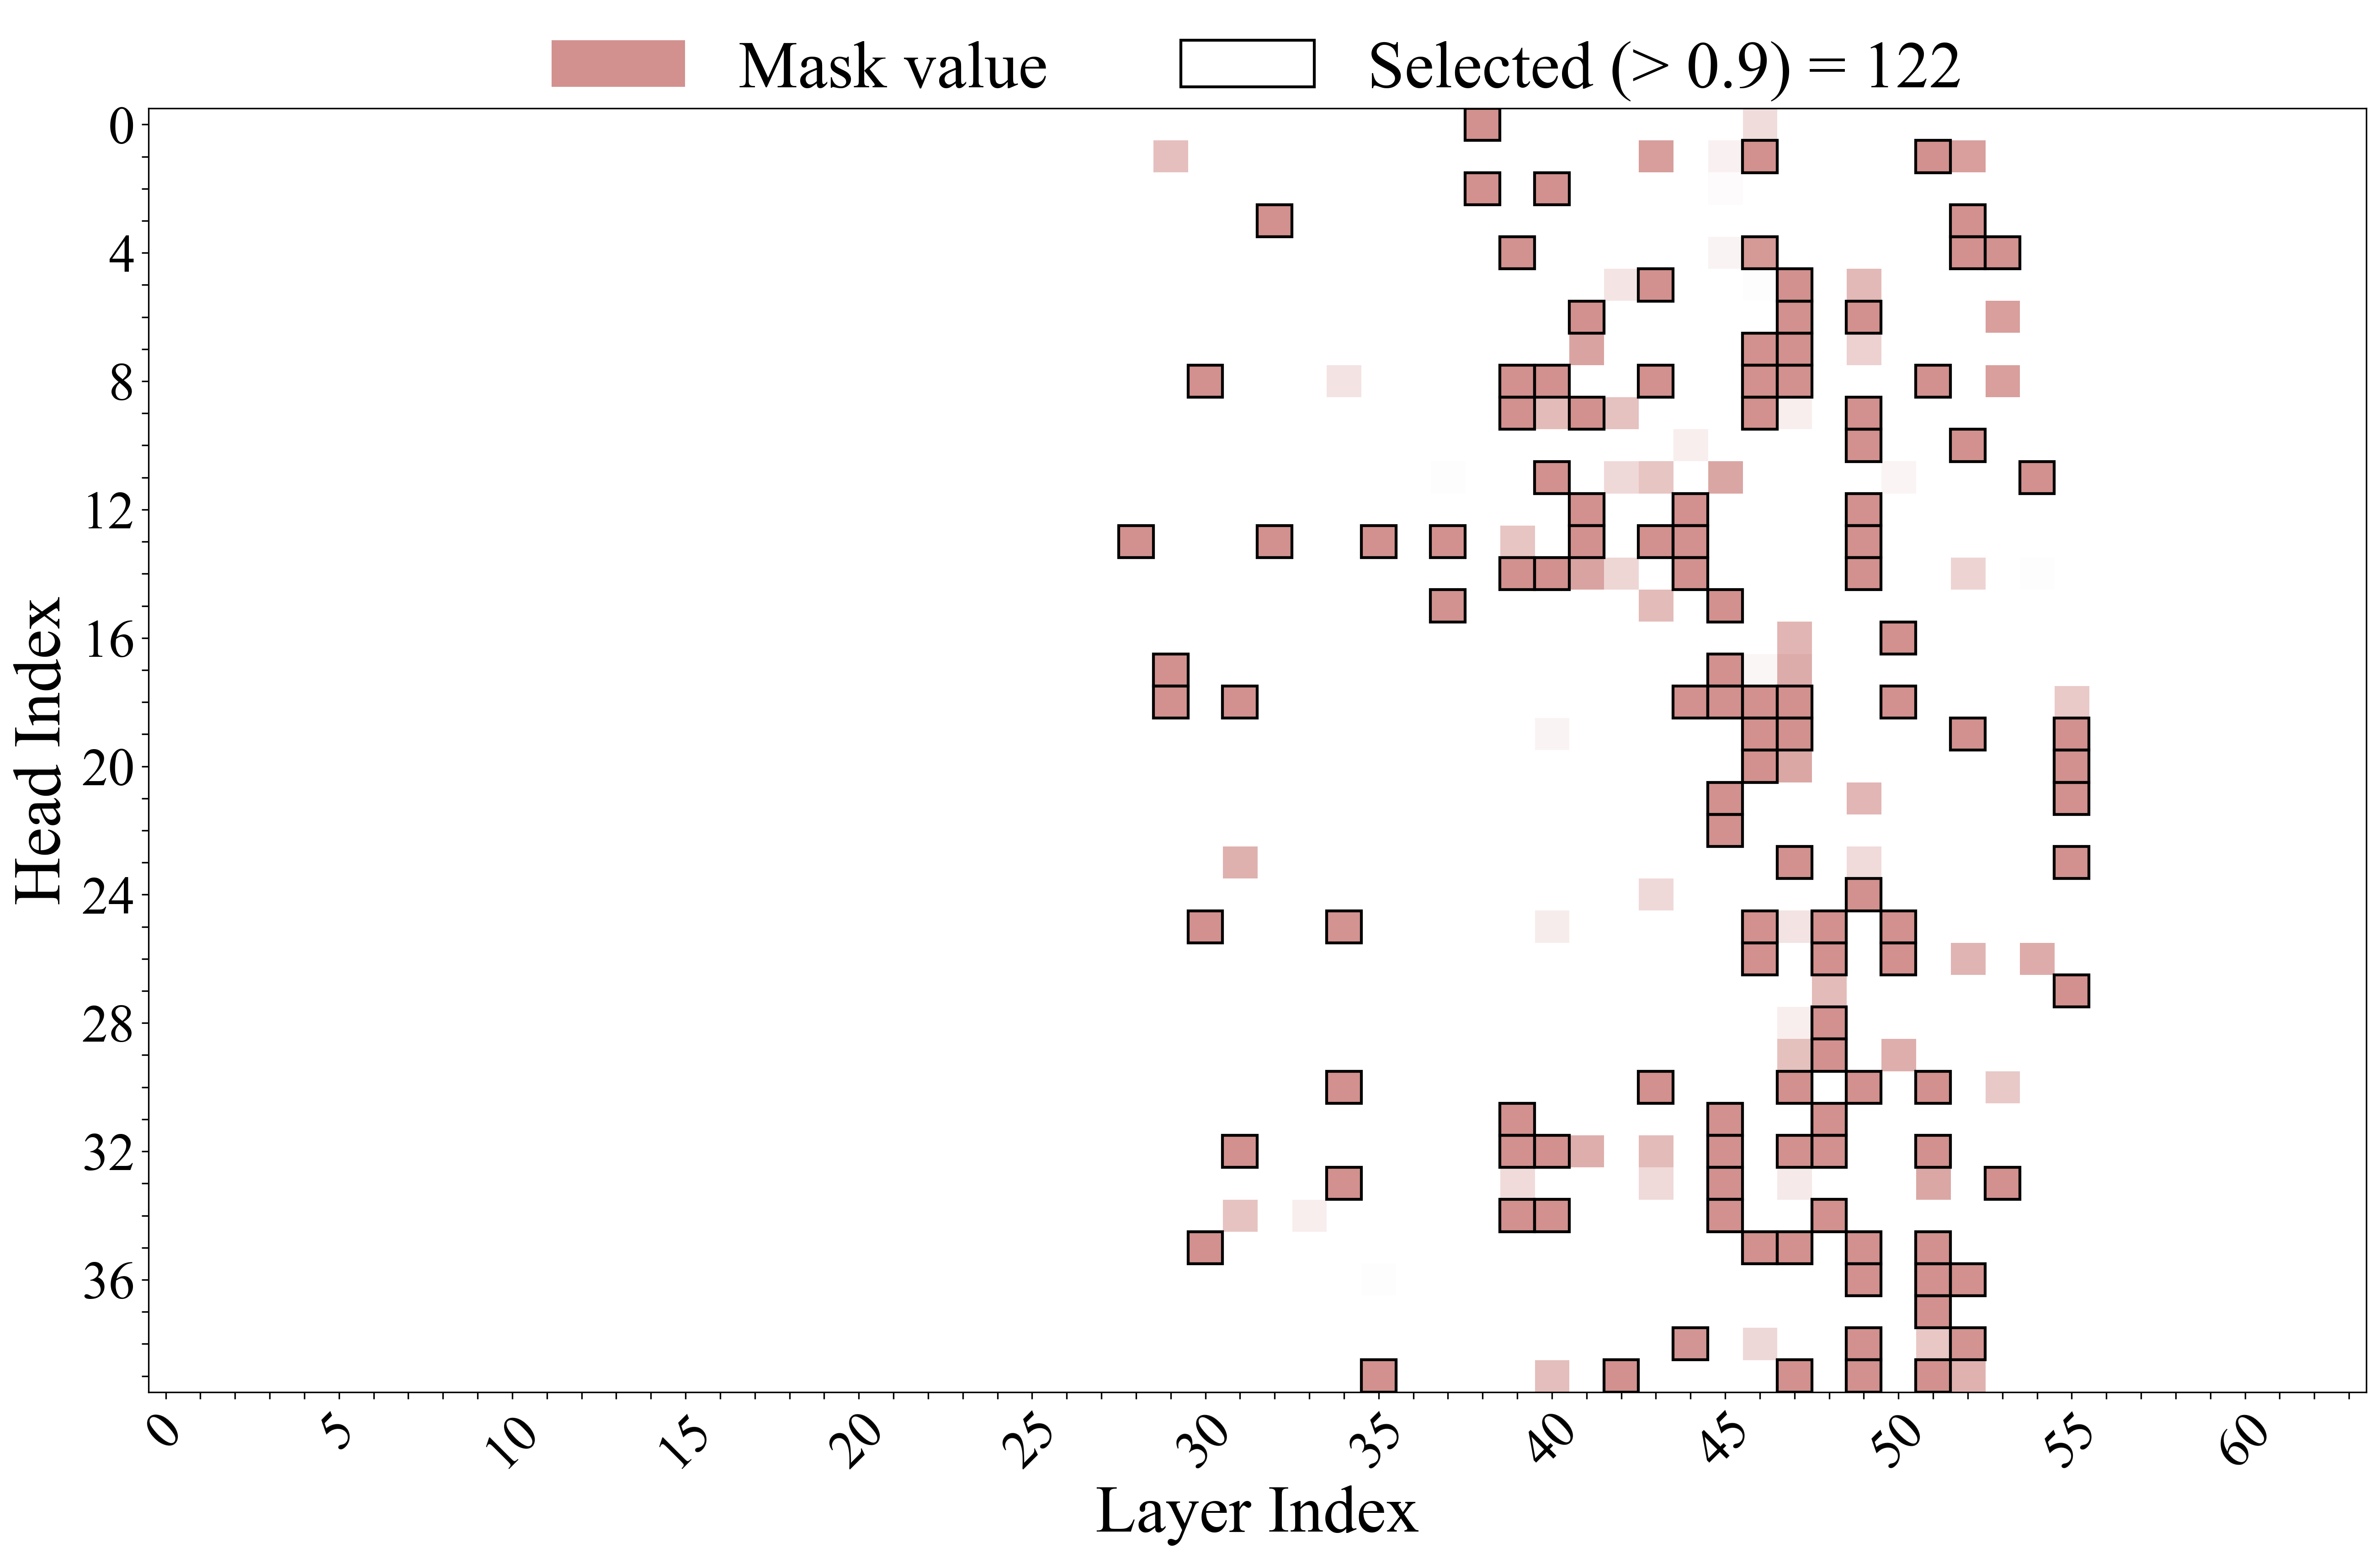

In [19]:
import matplotlib.patches as mpatches
from matplotlib.colors import LinearSegmentedColormap
from matplotlib import pyplot as plt
from matplotlib import patches

plt.rcParams["figure.dpi"] = 300
plt.rcParams["font.family"] = "Times New Roman"

SMALL_SIZE = 28
MEDIUM_SIZE = 35
BIGGER_SIZE = 40

plt.rc("font", size=SMALL_SIZE)
plt.rc("axes", titlesize=BIGGER_SIZE)
plt.rc("axes", labelsize=MEDIUM_SIZE)
plt.rc("xtick", labelsize=SMALL_SIZE)
plt.rc("ytick", labelsize=SMALL_SIZE)
plt.rc("legend", fontsize=SMALL_SIZE)
plt.rc("figure", titlesize=BIGGER_SIZE)


def get_ticks(ticks, skip=5, offset=0):
    ret = []
    for i in ticks:
        actual_layer = i + offset
        if actual_layer % skip == 0:
            ret.append(str(actual_layer))
        else:
            ret.append("")
    return ret


_n_heads = mt.config.num_attention_heads
_n_layer = mt.n_layer

# Build continuous mask matrix: shape (n_heads, n_layer)
# Layers outside the optimized range stay 0.
function_mask = torch.zeros((_n_heads, _n_layer), dtype=torch.float32)
for i, layer_idx in enumerate(LAYERS):
    function_mask[:, layer_idx] = mask.values[i].detach().cpu()

# Create figure and axis
fig, ax = plt.subplots(figsize=(18, 12))

colors = ["white", "#BF625E"]
cmap = LinearSegmentedColormap.from_list("white_orange", colors, N=100)

ax.imshow(
    function_mask.numpy(),
    cmap=cmap,
    aspect="auto",
    vmin=0,
    vmax=1,
    alpha=0.7,
)

# Black border around selected heads (mask value > 0.5)
for layer_idx, head_idx in selected_heads:
    rect = patches.Rectangle(
        (layer_idx - 0.5, head_idx - 0.5),
        1,
        1,
        linewidth=1.5,
        edgecolor="black",
        facecolor="none",
    )
    ax.add_patch(rect)

plt.xlabel("Layer Index")
plt.ylabel("Head Index")
plt.xticks(
    ticks=range(_n_layer),
    labels=get_ticks(range(_n_layer)),
    rotation=45,
)
plt.yticks(
    ticks=range(_n_heads),
    labels=get_ticks(range(_n_heads), skip=4),
)

legend_elements = [
    mpatches.Patch(facecolor="#BF625E", alpha=0.7, label="Mask value"),
    mpatches.Patch(
        facecolor="white",
        edgecolor="black",
        linewidth=1.5,
        label=f"Selected (> {threshold}) = {len(selected_heads)}",
    ),
]
ax.legend(
    handles=legend_elements,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.1),
    ncol=2,
    fontsize=MEDIUM_SIZE,
    frameon=False,
)

plt.tight_layout()
plt.show()


In [7]:
top_heads = sorted(
    selected_heads, key=lambda x: mask.values[LAYERS.index(x[0]), x[1]], reverse=True
)
for layer_idx, head_idx in top_heads:
    mask_val = mask.values[LAYERS.index(layer_idx), head_idx].item()
    print(f"Layer {layer_idx} Head {head_idx} (mask={mask_val:.4f}):")

Layer 28 Head 13 (mask=1.0000):
Layer 29 Head 17 (mask=1.0000):
Layer 29 Head 18 (mask=1.0000):
Layer 30 Head 8 (mask=1.0000):
Layer 30 Head 25 (mask=1.0000):
Layer 30 Head 35 (mask=1.0000):
Layer 31 Head 18 (mask=1.0000):
Layer 31 Head 32 (mask=1.0000):
Layer 32 Head 3 (mask=1.0000):
Layer 32 Head 13 (mask=1.0000):
Layer 34 Head 30 (mask=1.0000):
Layer 34 Head 33 (mask=1.0000):
Layer 35 Head 13 (mask=1.0000):
Layer 35 Head 39 (mask=1.0000):
Layer 38 Head 0 (mask=1.0000):
Layer 38 Head 2 (mask=1.0000):
Layer 39 Head 9 (mask=1.0000):
Layer 39 Head 14 (mask=1.0000):
Layer 39 Head 31 (mask=1.0000):
Layer 39 Head 32 (mask=1.0000):
Layer 39 Head 34 (mask=1.0000):
Layer 40 Head 2 (mask=1.0000):
Layer 40 Head 8 (mask=1.0000):
Layer 40 Head 11 (mask=1.0000):
Layer 40 Head 32 (mask=1.0000):
Layer 40 Head 34 (mask=1.0000):
Layer 41 Head 6 (mask=1.0000):
Layer 41 Head 9 (mask=1.0000):
Layer 41 Head 12 (mask=1.0000):
Layer 41 Head 13 (mask=1.0000):
Layer 42 Head 39 (mask=1.0000):
Layer 43 Head 5 (

## Check Attention Patterns

In [8]:
from src.goals.functional import supports_chat_template, apply_chat_template
from src.goals.data import IncompleteCodeDataset
import copy
from src.tokens import prepare_input


single_pred_dataset = IncompleteCodeDataset.load_dataset()
for sample in single_pred_dataset:
    print(sample.function_name)

PRED_NAME = "is_palindrome"

single_pred_sample = copy.deepcopy([
    d for d in single_pred_dataset if d.function_name == PRED_NAME
][0])
# single_pred_sample.code = single_pred_sample.code.replace("s: str", "word: str")
# single_pred_sample.code = single_pred_sample.code.replace("is_uppercase", "check_uppercase")
# single_pred_sample.function_name = "check_uppercase"

rich_print(single_pred_sample)

# Use an inconsequential (unprefilled) prompt to see the model's natural preference
# prefill = "1 -"
# prefill = "5"
prefill = ""

if supports_chat_template(mt):
    adv_prompt = apply_chat_template(
        mt=mt,
        user_query=single_pred_sample.instruction.strip()
        if hasattr(single_pred_sample, "instruction")
        else "",
        incomplete_code=single_pred_sample.code + prefill,
    )
else:
    adv_prompt = single_pred_sample.code + prefill

prefill_idx = adv_prompt.index(prefill.strip())
rich_print(
    f'"[white]{adv_prompt[:prefill_idx]}[/white][bright_yellow]{adv_prompt[prefill_idx:]}[/bright_yellow]"'
)

2026-04-01 10:34:35 src.goals.data INFO     Loaded 17 samples from /disk/u/arnab/Codes/Projects/goals/data/incomplete_code.json
is_odd
is_even
is_non_negative
is_negative
is_zero
is_palindrome
is_empty
is_uppercase
is_digit_string
is_vowel
is_power_of_two
is_sorted
has_duplicates
all_same
is_anagram
is_perfect_square
has_unique_elements


IncompleteCodeSample(
    instruction='Write a function in python that checks if a string is a palindrome.\n\n',
    code='def is_palindrome(s: str) -> bool:\n    return True if ',
    unit_tests=[
        ('racecar', True),
        ('hello', False),
        ('', True),
        ('a', True),
        ('ab', False),
        ('aba', True),
        ('abba', True)
    ],
    prefills={
        'aligned': ['', '(', 's', 's ==', 's == s', 's[::', 's[::-1]', '(s', 'list(', 'list(s)'],
        'adversarial': ['not', 'not (', 's +', '3', '1 +'],
        'inconsequential': ['bool(', 'True and', 'False or', '0 +']
    },
    function_name='is_palindrome',
    augmentation=None
)

"<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a function in python that checks if a string is a palindrome.<|im_end|>
<|im_start|>assistant
<code>
def is_palindrome(s: str) -> bool:
    return True if "

In [9]:
from src.goals.predicate_data import MultiPredicateDataset, TargetPredicate

multi_dataset = MultiPredicateDataset.load_dataset()

print(f"MultiPredicateDataset: {len(multi_dataset)} predicates")
print(f"IncompleteCodeDataset: {len(single_pred_dataset)} samples")
print(f"Available predicates: {[tp.name for tp in multi_dataset.groups]}")

# ── Pick target predicate + sample ───────────────────────────────────────────
PRED_NAME = "is_perfect_square"  # Change to pick a different predicate
SAMPLE_IDX = 2

target_predicate: TargetPredicate = next(tp for tp in multi_dataset.groups if tp.name == PRED_NAME)
sample = target_predicate.samples[SAMPLE_IDX]

print(f"Target predicate: {target_predicate.name!r}")
print(f"  P+: {target_predicate.p_plus.description}")
print(f"  P+ anchor tokens: {target_predicate.p_plus.anchor_patterns}")
if sample.p_minus:
    print(f"  P- (sample {SAMPLE_IDX}): {sample.p_minus.description}")
    print(f"  P- anchor tokens: {sample.p_minus.anchor_patterns}")
print(f"\nCode stub:\n{sample.code}")

2026-04-01 10:34:35 src.goals.predicate_data INFO     Loaded TargetPredicate 'has_unique_elements' with 3 sample(s) from /disk/u/arnab/Codes/Projects/goals/data/multi_predicate/has_unique_elements.json
2026-04-01 10:34:35 src.goals.predicate_data INFO     Loaded TargetPredicate 'is_anagram' with 4 sample(s) from /disk/u/arnab/Codes/Projects/goals/data/multi_predicate/is_anagram.json
2026-04-01 10:34:35 src.goals.predicate_data INFO     Loaded TargetPredicate 'is_palindrome' with 5 sample(s) from /disk/u/arnab/Codes/Projects/goals/data/multi_predicate/is_palindrome.json
2026-04-01 10:34:35 src.goals.predicate_data INFO     Loaded TargetPredicate 'is_perfect_square' with 4 sample(s) from /disk/u/arnab/Codes/Projects/goals/data/multi_predicate/is_perfect_square.json
2026-04-01 10:34:35 src.goals.predicate_data INFO     Loaded TargetPredicate 'is_power_of_two' with 3 sample(s) from /disk/u/arnab/Codes/Projects/goals/data/multi_predicate/is_power_of_two.json
2026-04-01 10:34:35 src.goals.pr

In [10]:
from src.goals.functional import supports_chat_template, apply_chat_template

# ── Build prompt ─────────────────────────────────────────────────────────────
prefill = ""

if supports_chat_template(mt):
    multi_prompt = apply_chat_template(
        mt=mt,
        user_query=sample.instruction.strip(),
        incomplete_code=sample.code + prefill,
    )
else:
    multi_prompt = sample.instruction + "<code>" + sample.code + prefill

rich_print(f'[white]"{multi_prompt}"[/white]')

"<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python function that returns True iff n is even and a perfect square.<|im_end|>
<|im_start|>assistant
<code>
def is_even_perfect_square(n: int) -> bool:
    """Return True iff n is a non-negative even integer and a perfect square."""
    return "

In [16]:
from src.tokens import find_token_range

tokenized_inputs = prepare_input([multi_prompt], tokenizer=mt, return_offsets_mapping=True)
offsets = tokenized_inputs.pop("offset_mapping")[0]  # List of (start_char, end_char) for each token

code_start, _ = find_token_range(
    string=multi_prompt,
    substring="<code>",
    tokenizer=mt,
    offset_mapping=offsets,
    occurrence=-1
)

In [17]:
import io
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import imageio.v3 as iio
from PIL import Image
from src.attention import get_attention_matrices, visualize_attn_matrix
import random, itertools
from src.functional import interpret_logits

MAX_NEW_TOKENS = 64
_STOP_IDS = (
    {mt.tokenizer.eos_token_id}
    | set(mt.tokenizer.encode("\n", add_special_tokens=False))
    | set(mt.tokenizer.encode("\n\n", add_special_tokens=False))
)
_CHECK_HEADS = top_heads
# _CHECK_HEADS = random.sample(
#     list(itertools.product(LAYERS, range(mt.config.num_attention_heads))),
#     k=len(top_heads),
# )

# ── Fixed canvas parameters ───────────────────────────────────────────────────
# 1 data unit = 1 character width (monospace 8pt).
# _FIG_W = _CHARS_PER_LINE * 0.6 * _FONTSIZE / 72  →  720 px at 120 dpi
_FONTSIZE       = 8      # pt, monospace
_DPI            = 120
_CHARS_PER_LINE = 90     # data-unit width of axes
_ROW_H          = 2.2   # row height in char-unit data coords
_TOK_PAD        = 0.4   # horizontal padding (char units) on each side of text
_TOK_GAP        = 0.5   # gap between tokens (char units)

# Worst-case rows: assume avg 5 chars/token
_MAX_VIS_TOKS = len(tokenized_inputs["input_ids"][0]) - code_start + MAX_NEW_TOKENS
_N_ROWS_FIXED = (_MAX_VIS_TOKS * 5 + _CHARS_PER_LINE - 1) // _CHARS_PER_LINE + 2

_FIG_W = _CHARS_PER_LINE * 0.6 * _FONTSIZE / 72          # inches
_FIG_H = _N_ROWS_FIXED * _ROW_H * _FONTSIZE / 72 + 0.45  # inches

# Glyph substitutions (defined as constants to avoid escape issues in f-strings)
_GLYPH_NL  = "\u21b5"   # ↵  newline
_GLYPH_TAB = "\u21e5"   # ⇥  tab
_GLYPH_DOT = "\u00b7"   # ·  space


def _display_tok(tok: str) -> str:
    """Un-escape _safe_token HTML subs and replace whitespace with visible glyphs."""
    # _safe_token replaces < > with fullwidth variants for HTML safety — undo that
    tok = tok.replace("\uff1c", "<").replace("\uff1e", ">")
    # Replace whitespace with visible glyphs
    tok = tok.replace("\n", _GLYPH_NL).replace("\r", _GLYPH_NL)
    tok = tok.replace("\t", _GLYPH_TAB)
    if tok.strip() == "" and len(tok) > 0:
        tok = _GLYPH_DOT * len(tok)
    return tok


def _is_newline_tok(tok: str) -> bool:
    """True if the raw token string contains a newline character."""
    return "\n" in tok or "\r" in tok


def _flow_layout(toks, chars_per_line, tok_pad, tok_gap):
    """Greedy inline-flow layout.
    Returns list of (x_left, row, box_width, display_str).
    Newline tokens force a hard line break (shown as ↵ at end of the line).
    """
    positions = []
    x, row = 0.0, 0
    for tok in toks:
        disp = _display_tok(tok)
        w = len(disp) + 2 * tok_pad
        if _is_newline_tok(tok):
            positions.append((x, row, w, disp))
            row += 1
            x = 0.0
            continue
        if x > 0 and x + w > chars_per_line:
            row += 1
            x = 0.0
        positions.append((x, row, w, disp))
        x += w + tok_gap
    return positions


def _aggregate_and_visualize_attn(attn_info, heads, q_index=-1, start_from=0):
    aggregated_attn = []
    for layer, head in heads:
        aggregated_attn.append(torch.Tensor(attn_info.get_attn_matrix(layer, head)))
    aggregated_attn = torch.stack(aggregated_attn, dim=0)  # (n_heads, seq, seq)
    mean_attn = aggregated_attn.mean(dim=0)                # (seq, seq)
    visualize_attn_matrix(mean_attn, attn_info.tokenized_prompt, q_index=q_index, start_from=start_from)
    return mean_attn


def _render_colored_tokens_frame(
    attn_row: torch.Tensor,
    tokens: list[str],
    step: int,
    generated_tok: str,
    start_from: int = 0,
    cmap_name: str = "Blues",
) -> Image.Image:
    """Inline-flow token visualization with widths proportional to token length."""
    vals = attn_row[start_from:].float().numpy()
    toks = tokens[start_from:]

    cmap = plt.get_cmap(cmap_name)
    vmax = vals.max() if vals.max() > 0 else 1.0

    positions = _flow_layout(toks, _CHARS_PER_LINE, _TOK_PAD, _TOK_GAP)
    y_top = _N_ROWS_FIXED * _ROW_H
    box_h = _ROW_H * 0.75

    fig, ax = plt.subplots(figsize=(_FIG_W, _FIG_H))
    ax.set_xlim(0, _CHARS_PER_LINE)
    ax.set_ylim(0, y_top)
    ax.axis("off")
    ax.set_title(
        f"step {step}  \u2192  '{_display_tok(generated_tok)}'",
        fontsize=9, pad=3, fontfamily="monospace",
    )

    last_idx = len(positions) - 1
    for i, (val, (x, row, w, disp)) in enumerate(zip(vals, positions)):
        y_bottom = y_top - (row + 1) * _ROW_H + (_ROW_H - box_h) / 2

        is_query = (i == last_idx)
        color = cmap(val / vmax)
        ax.add_patch(mpatches.FancyBboxPatch(
            (x, y_bottom), w, box_h,
            boxstyle="round,pad=0.15",
            facecolor=color,
            edgecolor="red" if is_query else "none",
            linewidth=1.5 if is_query else 0,
        ))

        brightness = 0.299 * color[0] + 0.587 * color[1] + 0.114 * color[2]
        ax.text(
            x + w / 2, y_bottom + box_h / 2, disp,
            ha="center", va="center",
            fontsize=_FONTSIZE, color="black" if brightness > 0.45 else "white",
            fontfamily="monospace",
        )

    fig.tight_layout(pad=0.2)
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=_DPI, bbox_inches=None)
    plt.close(fig)
    buf.seek(0)
    return Image.open(buf).copy()


print(len(tokenized_inputs["input_ids"][0]), len(tokenized_inputs["attention_mask"][0]))
generated = []
frames: list[Image.Image] = []

with torch.no_grad():
    device = next(mt._model.parameters()).device
    for step in range(MAX_NEW_TOKENS):
        cur_attn_info = get_attention_matrices(tokenized_inputs, mt, value_weighted=True)
        next_token_id = torch.argmax(cur_attn_info.logits).item()
        if next_token_id in _STOP_IDS:
            break
        
        generated.append(next_token_id)
        generated_tok = mt.tokenizer.decode([next_token_id])

        mean_attn = _aggregate_and_visualize_attn(
            cur_attn_info, _CHECK_HEADS, q_index=-1, start_from=code_start
        )
        frames.append(_render_colored_tokens_frame(
            attn_row=mean_attn[-1],
            tokens=cur_attn_info.tokenized_prompt,
            step=step,
            generated_tok=generated_tok,
            start_from=code_start,
        ))

        tokenized_inputs["input_ids"] = torch.cat(
            [tokenized_inputs["input_ids"], torch.tensor([[next_token_id]], device=device)], dim=1
        )
        tokenized_inputs["attention_mask"] = torch.cat(
            [tokenized_inputs["attention_mask"], torch.tensor([[1]], device=device)], dim=1
        )
        rich_print(
            f'"[white]{mt.tokenizer.decode(tokenized_inputs["input_ids"][0][-10:-1])}[/white]'
            f'[bright_yellow]{mt.tokenizer.decode(tokenized_inputs["input_ids"][0][-1:])!r}[/bright_yellow]"'
        )

print(f"\nCollected {len(frames)} frames.")
sizes = {f.size for f in frames}
print(f"Frame sizes: {sizes} {'OK' if len(sizes) == 1 else 'MISMATCH'}")

101 101


2026-04-01 10:40:02 PIL.PngImagePlugin DEBUG    STREAM b'IHDR' 16 13
2026-04-01 10:40:02 PIL.PngImagePlugin DEBUG    STREAM b'tEXt' 41 58
2026-04-01 10:40:02 PIL.PngImagePlugin DEBUG    STREAM b'pHYs' 111 9
2026-04-01 10:40:02 PIL.PngImagePlugin DEBUG    STREAM b'IDAT' 132 18641


" integer and a perfect square."""
    return '0'"

2026-04-01 10:40:02 PIL.PngImagePlugin DEBUG    STREAM b'IHDR' 16 13
2026-04-01 10:40:02 PIL.PngImagePlugin DEBUG    STREAM b'tEXt' 41 58
2026-04-01 10:40:02 PIL.PngImagePlugin DEBUG    STREAM b'pHYs' 111 9
2026-04-01 10:40:02 PIL.PngImagePlugin DEBUG    STREAM b'IDAT' 132 19400


" and a perfect square."""
    return 0' <='"

2026-04-01 10:40:02 PIL.PngImagePlugin DEBUG    STREAM b'IHDR' 16 13
2026-04-01 10:40:02 PIL.PngImagePlugin DEBUG    STREAM b'tEXt' 41 58
2026-04-01 10:40:02 PIL.PngImagePlugin DEBUG    STREAM b'pHYs' 111 9
2026-04-01 10:40:02 PIL.PngImagePlugin DEBUG    STREAM b'IDAT' 132 19837


... (36 outputs left out)

" and int(n**0.5)**2' =='"

2026-04-01 10:40:09 PIL.PngImagePlugin DEBUG    STREAM b'IHDR' 16 13
2026-04-01 10:40:09 PIL.PngImagePlugin DEBUG    STREAM b'tEXt' 41 58
2026-04-01 10:40:09 PIL.PngImagePlugin DEBUG    STREAM b'pHYs' 111 9
2026-04-01 10:40:09 PIL.PngImagePlugin DEBUG    STREAM b'IDAT' 132 23203


" int(n**0.5)**2 ==' n'"


Collected 22 frames.
Frame sizes: {(720, 288)} OK


In [13]:
mt.tokenizer.batch_decode(generated)[0]

'0 <= n and n % 2 == 0 and int(n**0.5)**2 == n'

In [14]:
GIF_PATH = "results/attn_steps.gif"
os.makedirs("results", exist_ok=True)

iio.imwrite(
    GIF_PATH,
    [np.array(f) for f in frames],
    extension=".gif",
    duration=800,   # ms per frame — increase to slow down
    loop=0,         # 0 = loop forever
)
print(f"Saved {len(frames)}-frame GIF → {GIF_PATH}")

2026-04-01 10:34:44 PIL.Image DEBUG    Importing AvifImagePlugin
2026-04-01 10:34:44 PIL.Image DEBUG    Importing BlpImagePlugin
2026-04-01 10:34:44 PIL.Image DEBUG    Importing BmpImagePlugin
2026-04-01 10:34:44 PIL.Image DEBUG    Importing BufrStubImagePlugin
2026-04-01 10:34:44 PIL.Image DEBUG    Importing CurImagePlugin
2026-04-01 10:34:44 PIL.Image DEBUG    Importing DcxImagePlugin
2026-04-01 10:34:44 PIL.Image DEBUG    Importing DdsImagePlugin


2026-04-01 10:34:44 PIL.Image DEBUG    Importing EpsImagePlugin
2026-04-01 10:34:44 PIL.Image DEBUG    Importing FitsImagePlugin
2026-04-01 10:34:44 PIL.Image DEBUG    Importing FliImagePlugin
2026-04-01 10:34:44 PIL.Image DEBUG    Importing FpxImagePlugin
2026-04-01 10:34:44 PIL.Image DEBUG    Image: failed to import FpxImagePlugin: No module named 'olefile'
2026-04-01 10:34:44 PIL.Image DEBUG    Importing FtexImagePlugin
2026-04-01 10:34:44 PIL.Image DEBUG    Importing GbrImagePlugin
2026-04-01 10:34:44 PIL.Image DEBUG    Importing GifImagePlugin
2026-04-01 10:34:44 PIL.Image DEBUG    Importing GribStubImagePlugin
2026-04-01 10:34:44 PIL.Image DEBUG    Importing Hdf5StubImagePlugin
2026-04-01 10:34:44 PIL.Image DEBUG    Importing IcnsImagePlugin
2026-04-01 10:34:44 PIL.Image DEBUG    Importing IcoImagePlugin
2026-04-01 10:34:44 PIL.Image DEBUG    Importing ImImagePlugin
2026-04-01 10:34:44 PIL.Image DEBUG    Importing ImtImagePlugin
2026-04-01 10:34:44 PIL.Image DEBUG    Importing Ip

## Clock Signal (`c`) Probe

Test whether goal-completion progress is linearly encoded in the residual stream.

Binary classification: **"in progress"** (within the P+ anchor pattern span) vs **"not in progress"** (pre-P+, P-, post-`</code>`, transition tokens).

Pipeline:
1. `generate_and_cache_latents` — greedy generation + single forward pass to save residual / MLP / attn at all token positions and layers
2. `find_in_progress_mask` — apply `anchor_patterns` regex on generated text, map char spans → token indices
3. `collect_probe_examples` → `train_probe` — balanced logistic regression per layer
4. Visualize balanced accuracy vs layer index

In [4]:
from src.goals.predicate_data import MultiPredicateDataset, TargetPredicate

multi_dataset = MultiPredicateDataset.load_dataset()

print(f"MultiPredicateDataset: {len(multi_dataset)} predicates")
print(f"Available predicates: {[tp.name for tp in multi_dataset.groups]}")

# ── Pick target predicate + sample ───────────────────────────────────────────
PRED_NAME = "is_perfect_square"  # Change to pick a different predicate
SAMPLE_IDX = 2

target_predicate: TargetPredicate = next(tp for tp in multi_dataset.groups if tp.name == PRED_NAME)
sample = target_predicate.samples[SAMPLE_IDX]

print(f"Target predicate: {target_predicate.name!r}")
print(f"  P+: {target_predicate.p_plus.description}")
print(f"  P+ anchor tokens: {target_predicate.p_plus.anchor_patterns}")
if sample.p_minus:
    print(f"  P- (sample {SAMPLE_IDX}): {sample.p_minus.description}")
    print(f"  P- anchor tokens: {sample.p_minus.anchor_patterns}")
print(f"\nCode stub:\n{sample.code}")

2026-04-02 17:18:36 src.goals.predicate_data INFO     Loaded TargetPredicate 'has_unique_elements' with 3 sample(s) from /disk/u/arnab/Codes/Projects/goals/data/multi_predicate/has_unique_elements.json
2026-04-02 17:18:36 src.goals.predicate_data INFO     Loaded TargetPredicate 'is_anagram' with 4 sample(s) from /disk/u/arnab/Codes/Projects/goals/data/multi_predicate/is_anagram.json
2026-04-02 17:18:36 src.goals.predicate_data INFO     Loaded TargetPredicate 'is_palindrome' with 5 sample(s) from /disk/u/arnab/Codes/Projects/goals/data/multi_predicate/is_palindrome.json
2026-04-02 17:18:36 src.goals.predicate_data INFO     Loaded TargetPredicate 'is_perfect_square' with 4 sample(s) from /disk/u/arnab/Codes/Projects/goals/data/multi_predicate/is_perfect_square.json
2026-04-02 17:18:36 src.goals.predicate_data INFO     Loaded TargetPredicate 'is_power_of_two' with 3 sample(s) from /disk/u/arnab/Codes/Projects/goals/data/multi_predicate/is_power_of_two.json
2026-04-02 17:18:36 src.goals.pr

In [5]:
import re
import numpy as np
import torch
from pathlib import Path
from sklearn.metrics import balanced_accuracy_score

from src.goals.clock_probe import (
    DEFAULT_HARMLESS_PREFILLS,
    LinearProbe,
    ProbeRecord,
    SequenceLatents,
    batch_generate,
    cache_latents_batch,
    collect_probe_examples,
    eval_probe,
    evaluate_gen_ids,
    find_in_progress_mask,
    find_in_progress_mask_oracle,
    load_probe_dataset,
    save_probe_dataset,
    train_probe,
)

# ── Configuration ──────────────────────────────────────────────────────────────────
TEST_PREDICATES = ["is_palindrome", "is_perfect_square", "is_prime"]

PROBE_LAYERS = list(range(mt.n_layer))  # all layers; updated below if data uses fewer
PROBE_REP_TYPE = "residual"             # "residual" | "mlp" | "attn"

MAX_GEN_TOKENS = 128
EVAL_TIMEOUT = 5

# Directories for the labeled probe dataset (one .pt per record per split)
_PROBE_ROOT = Path("../results/clock_probe") / mt.name.split("/")[-1]
TRAIN_DIR   = _PROBE_ROOT / "train"
TEST_DIR    = _PROBE_ROOT / "test"

print(f"Test predicates (held out):  {TEST_PREDICATES}")
print(f"Probe layers:                {PROBE_LAYERS[0]}–{PROBE_LAYERS[-1]}  ({len(PROBE_LAYERS)} layers)")
print(f"Train dir:                   {TRAIN_DIR}")
print(f"Test dir:                    {TEST_DIR}")


Test predicates (held out):  ['is_palindrome', 'is_perfect_square', 'is_prime']
Probe layers:                0–63  (64 layers)
Train dir:                   ../results/clock_probe/Qwen2.5-Coder-32B-Instruct/train
Test dir:                    ../results/clock_probe/Qwen2.5-Coder-32B-Instruct/test


In [6]:
# ── Stage 1: Augmentation ──────────────────────────────────────────────────────
# Pick one predicate + sample to test the augmentation pipeline interactively.

from src.goals.clock_probe import augment_sample_for_probe

_DEMO_PRED = "is_anagram"
_demo_tp = next(tp for tp in multi_dataset.groups if tp.name == _DEMO_PRED)
_demo_sample = _demo_tp.samples[2]
print(f"P- description: {_demo_sample.p_minus.description if _demo_sample.p_minus else 'No P-'}")

variants = augment_sample_for_probe(_demo_tp, _demo_sample)
print(f"Predicate: {_DEMO_PRED!r}  |  {len(variants)} (sample, prefill) pairs\n")

for aug_s, pf in variants:
    aug_type = aug_s.augmentation[-1]["type"] if aug_s.augmentation else "original"
    print(f"  [{aug_type:<22}]  prefill={repr(pf):<18}  fn={aug_s.function_name}")

print("\nExample augmented code stub (variable_rename, s→text):")
renamed_samples = [(s, pf) for s, pf in variants if s.augmentation and s.augmentation[-1]["type"] == "swap_predicate_order"]
if renamed_samples:
    rich_print(f"[white]{renamed_samples[0][0].code}[/white]")

P- description: check whether pair[0] != pair[1]
Predicate: 'is_anagram'  |  36 (sample, prefill) pairs

  [original              ]  prefill=''                  fn=is_nontrivial_anagram
  [original              ]  prefill='True and '         fn=is_nontrivial_anagram
  [original              ]  prefill='False or '         fn=is_nontrivial_anagram
  [original              ]  prefill='bool('             fn=is_nontrivial_anagram
  [variable_rename       ]  prefill=''                  fn=is_nontrivial_anagram
  [variable_rename       ]  prefill='True and '         fn=is_nontrivial_anagram
  [variable_rename       ]  prefill='False or '         fn=is_nontrivial_anagram
  [variable_rename       ]  prefill='bool('             fn=is_nontrivial_anagram
  [variable_rename       ]  prefill=''                  fn=is_nontrivial_anagram
  [variable_rename       ]  prefill='True and '         fn=is_nontrivial_anagram
  [variable_rename       ]  prefill='False or '         fn=is_nontrivial_anagram
  [v

def is_nontrivial_anagram(pair: tuple) -> bool:
    """Return True iff pair[0] and pair[1] are anagrams of each other. and the strings in pair are anagrams of each
other."""
    return 

In [7]:
# for aug_sample, prefill in variants:
#     print(aug_sample.p_minus.description if aug_sample.p_minus else "No P-")

In [8]:
# ── Stage 2: Generation + evaluation ──────────────────────────────────────────
# Test generate_and_evaluate_sample on one (sample, prefill) pair.
# Shows the decoded generation and the unit-test verdict.
from src.goals.functional import apply_chat_template
from src.goals.clock_probe import generate_and_evaluate_sample

_demo_aug_sample, _demo_prefill = variants[0]  # original sample, empty prefill

_demo_prompt = apply_chat_template(
    mt=mt,
    user_query=_demo_aug_sample.instruction.strip(),
    incomplete_code=_demo_aug_sample.code + _demo_prefill,
)

_stage2_result = generate_and_evaluate_sample(
    mt=mt,
    prompt=_demo_prompt,
    sample=_demo_aug_sample,
    prefill=_demo_prefill,
    max_new_tokens=MAX_GEN_TOKENS,
    # stop_ids=_STOP_IDS_PROBE,
    eval_timeout=EVAL_TIMEOUT,
)

if _stage2_result is not None:
    _prompt_ids, _gen_ids = _stage2_result
    _gen_text = mt.tokenizer.decode(_gen_ids, skip_special_tokens=False)
    print(f"PASSED — {len(_gen_ids)} generated tokens")
    print(f"Generation: {repr(_gen_text[:200])}")
else:
    print("FAILED / TIMEOUT — generation did not pass unit tests")

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


The attention mask is not set and cannot be inferred from input because pad token is same as eos token. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.
You have set `compile_config`, but we are unable to meet the criteria for compilation. Compilation will be skipped.


True
False
False
PASSED — 128 generated tokens
Generation: ' sorted(pair[0]) == sorted(pair[1]) and pair[0] != pair[1]\n\n# Example usage:\nprint(is_nontrivial_anagram(("listen", "silent")))  # True\nprint(is_nontrivial_anagram(("hello", "bello")))    # False\nprin'


In [9]:
from src.goals.eval import evaluate_single_code
from src.functional import generate_with_patch
from src.goals.data import CodeGenerations, Code
from src.goals.eval import run_evaluation

_gen = generate_with_patch(
    mt=mt,
    inputs=_demo_prompt,
    max_new_tokens=MAX_GEN_TOKENS,
    do_sample=False,
    remove_prefix=True,
    n_gen_per_prompt=1
)

rich_print(
    f'"[white]{_demo_prompt}[/white][bright_yellow]{_gen[0]}[/bright_yellow]"'
)

code_stop_tag: str | None = "</code>"
lm_completion = _gen[0]
if code_stop_tag:
    cur_stop_tag = code_stop_tag if code_stop_tag in lm_completion else "\n"
    lm_completion = lm_completion.split(cur_stop_tag)[0].strip()

incomplete_prefix = _demo_aug_sample.code + _demo_prefill
if incomplete_prefix.endswith(" ") is False:
    incomplete_prefix += " "
full_code = incomplete_prefix + lm_completion
rich_print(f"[white]{full_code}[/white]")

eval = evaluate_single_code(
    full_code = full_code,
    unit_tests = _demo_aug_sample.unit_tests,
    function_name = _demo_aug_sample.function_name,
)
eval

"<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python function that accepts a pair of strings and returns True iff the two strings are anagrams of each 
other and are not identical.<|im_end|>
<|im_start|>assistant
<code>
def is_nontrivial_anagram(pair: tuple) -> bool:
    """Return True iff the strings in pair are anagrams of each other and are not identical."""
    return  sorted(pair[0]) == sorted(pair[1]) and pair[0] != pair[1]

# Example usage:
print(is_nontrivial_anagram(("listen", "silent")))  # True
print(is_nontrivial_anagram(("hello", "bello")))    # False
print(is_nontrivial_anagram(("abc", "abc")))        # False
</code>

This function `is_nontrivial_anagram` takes a tuple of two strings as input. It checks if the sorted characters of 
both strings are equal (which would mean they are anagrams) and also ensures that the strings are not identical"

def is_nontrivial_anagram(pair: tuple) -> bool:
    """Return True iff the strings in pair are anagrams of each other and are not identical."""
    return sorted(pair[0]) == sorted(pair[1]) and pair[0] != pair[1]

# Example usage:
print(is_nontrivial_anagram(("listen", "silent")))  # True
print(is_nontrivial_anagram(("hello", "bello")))    # False
print(is_nontrivial_anagram(("abc", "abc")))        # False

True
False
False


SingleCodeEval(code='def is_nontrivial_anagram(pair: tuple[str, str]) -> bool:\n    """Return True iff the strings in pair are anagrams of each other and are not identical."""\n    return sorted(pair[0]) == sorted(pair[1]) and pair[0] != pair[1]\n\n# Example usage:\nprint(is_nontrivial_anagram(("listen", "silent")))  # True\nprint(is_nontrivial_anagram(("hello", "bello")))    # False\nprint(is_nontrivial_anagram(("abc", "abc")))        # False', verdict='PASSED', unit_test_results=[UnitTestResult(input=['listen', 'silent'], expected=True, actual='True', passed=True, error=None), UnitTestResult(input=['abc', 'abc'], expected=False, actual='False', passed=True, error=None), UnitTestResult(input=['abc', 'bca'], expected=True, actual='True', passed=True, error=None), UnitTestResult(input=['abc', 'abd'], expected=False, actual='False', passed=True, error=None), UnitTestResult(input=['', ''], expected=False, actual='False', passed=True, error=None), UnitTestResult(input=['a', 'a'], expected=

In [10]:
# rich_print(eval)

In [11]:
# _demo_aug_sample.p_minus

In [12]:
# ── Stage 3: Latent caching ────────────────────────────────────────────────────
# Cache residual / MLP / attn activations for the passing generation from stage 2.
# (Requires _stage2_result to be non-None from the cell above.)
from src.goals.clock_probe import cache_latents_for_sequence

assert _stage2_result is not None, (
    "Run stage 2 cell first and ensure generation passes."
)

_demo_lat = cache_latents_for_sequence(
    mt=mt,
    prompt_ids=_prompt_ids,
    gen_ids=_gen_ids,
    layers=PROBE_LAYERS,
    include_mlp=True,
    include_attn=True,
)

print("SequenceLatents:")
print(f"  prompt_len:  {_demo_lat.prompt_len}")
print(f"  gen_ids:     {len(_demo_lat.gen_ids)} tokens")
print(
    f"  residual:    {len(_demo_lat.residual)} layers, each shape {next(iter(_demo_lat.residual.values())).shape}"
)
print(f"  mlp:         {len(_demo_lat.mlp)} layers")
print(f"  attn:        {len(_demo_lat.attn)} layers")

# Sanity: apply anchor_patterns and check that some tokens are marked in-progress
anchor_patterns = (
    _demo_tp.p_plus.anchor_patterns + _demo_aug_sample.p_minus.anchor_patterns
)
# anchor_patterns = list(set(anchor_patterns))  # deduplicate
_demo_masks = find_in_progress_mask_oracle(
    latents=_demo_lat,
    p_plus_description=_demo_tp.p_plus.description,
    p_minus_description=_demo_aug_sample.p_minus.description,
    tokenizer=mt.tokenizer,
    prefill=_demo_prefill,
)
_demo_mask = torch.stack([torch.tensor(mask) for mask in _demo_masks], dim=0).any(
    dim=0
)  # (seq_len,) bool tensor indicating in-progress tokens

print(
    f"\nin_progress_mask: {_demo_mask.sum()}/{len(_demo_mask)} tokens labeled in-progress"
)
gen_toks = [mt.tokenizer.decode(tok) for tok in _demo_lat.gen_ids]
formatted_gen = ""
for i, (tok, lbl) in enumerate(zip(gen_toks[:50], _demo_mask[:50])):
    formatted_tok = (
        f"[bright_green]{tok}[/bright_green]" if lbl else f"[white]{tok}[/white]"
    )
    formatted_gen += formatted_tok
rich_print(formatted_gen)

SequenceLatents:
  prompt_len:  120
  gen_ids:     128 tokens
  residual:    64 layers, each shape torch.Size([128, 5120])
  mlp:         64 layers
  attn:        64 layers
2026-04-02 17:18:59 httpx DEBUG    load_ssl_context verify=True cert=None trust_env=True http2=False
2026-04-02 17:18:59 httpx DEBUG    load_verify_locations cafile='/disk/u/arnab/miniconda3/envs/goals/lib/python3.11/site-packages/certifi/cacert.pem'
2026-04-02 17:18:59 src.utils.oracle_llms DEBUG    found cached claude response for 156571678dd3181a017590b1ed768fa4 - loading

Oracle response:
Looking at the generated code, I can identify the two predicates:

- `sorted(pair[0]) == sorted(pair[1])` implements P+ (anagram check)
- `pair[0] != pair[1]` implements P- (non-identical check)

These are separate, distinct subexpressions joined by `and`, so they can be tagged independently.

<p_plus>sorted(pair[0]) == sorted(pair[1])</p_plus>
<p_minus>pair[0] != pair[1]</p_minus>

in_progress_mask: 20/128 tokens labeled in-pr

 sorted(pair[0]) == sorted(pair[1]) and pair[0] != pair[1]

# Example usage:
print(is_nontrivial_anagram(("listen", "silent")))  # True
print(is_nontrivial_anagram(("

In [13]:
tp = multi_dataset.groups[0]
s = tp.samples[0]
s.is_original

True

In [14]:
# ── Load cached probe dataset from disk ─────────────────────────────────────────────
train_records = load_probe_dataset(TRAIN_DIR)
test_records  = load_probe_dataset(TEST_DIR)

# Tuples of (SequenceLatents, mask, description) consumed by probe training cells
train_examples = [(r.latents, r.in_progress_mask, r.predicate_description) for r in train_records]
test_examples  = [(r.latents, r.in_progress_mask, r.predicate_description) for r in test_records]

print(f"Train: {len(train_records):4d} records")
print(f"  Predicates: {sorted({r.predicate_name for r in train_records})}")
print(f"Test:  {len(test_records):4d} records")
print(f"  Predicates: {sorted({r.predicate_name for r in test_records})}")

# Sync PROBE_LAYERS to whatever layers are actually cached on disk
if train_records:
    _avail = sorted(train_records[0].latents.residual.keys())
    if _avail != PROBE_LAYERS:
        print(f"\nNote: data cached for layers {_avail[0]}–{_avail[-1]}; updating PROBE_LAYERS.")
        PROBE_LAYERS = _avail


  0%|          | 0/442 [00:00<?, ?it/s]

100%|██████████| 22/22 [00:01<00:00, 21.91it/s]

Train:  442 records
  Predicates: ['is_anagram', 'is_palindrome', 'is_power_of_two', 'is_sorted']
Test:    22 records
  Predicates: ['has_unique_elements', 'is_perfect_square']


In [15]:
# Inspect a single record:
r = train_records[100]
gen_toks = [mt.tokenizer.decode(tok) for tok in r.latents.gen_ids]
view_msg = ""
for tok, lbl in zip(gen_toks[:50], r.in_progress_mask[:50]):
    view_tok = f"[bright_green]{tok}[/bright_green]" if lbl else f"[yellow]{tok}[/yellow]"
    view_msg += view_tok

rich_print(f"[white]{r.prompt}[/white]" + view_msg)

<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python function that returns True iff the string contains only alphabetic characters and is a 
palindrome.<|im_end|>
<|im_start|>assistant
<code>
def is_alpha_palindrome(input_str: str) -> bool:
    """Return True iff input_str contains only alphabetic characters and is a palindrome."""
    return False or  (input_str.isalpha() and input_str == input_str[::-1])
</code>

This function first checks if the string contains only alphabetic characters using `isalpha()` method. Then it 
checks if the string is equal to its reverse (`input

In [17]:
r.__dict__.keys()

dict_keys(['predicate_name', 'predicate_description', 'prefill', 'prompt', 'latents', 'p_plus_mask', 'p_minus_mask'])

In [18]:
r.latents.__dict__.keys()

dict_keys(['prompt_len', 'prompt_ids', 'gen_ids', 'full_text', 'residual', 'code_start', 'code_residual', 'code_mlp', 'code_attn', 'mlp', 'attn'])

In [19]:
len(r.latents.prompt_ids)

107

In [20]:
print("".join([mt.tokenizer.decode(tok) for tok in r.latents.prompt_ids[r.latents.code_start:]]))


<code>
def is_alpha_palindrome(input_str: str) -> bool:
    """Return True iff input_str contains only alphabetic characters and is a palindrome."""
    return False or 


In [21]:
r.latents.code_residual[20].shape, len(r.latents.gen_ids)

(torch.Size([39, 5120]), 96)

In [22]:
from src.functional import logit_lens

token_idx = 0
print(f"{gen_toks[token_idx]=}  |  in_progress={r.in_progress_mask[token_idx]}")
logit_lens(
    mt=mt,
    h=r.latents.code_residual[63][-1].to(mt.dtype).to(mt.device),
)

gen_toks[token_idx]=' ('  |  in_progress=True


[PredictedToken(token=' (', prob=0.8515625, logit=23.0, token_id=320, metadata=None),
 PredictedToken(token=' input', prob=0.06982421875, logit=20.5, token_id=1946, metadata=None),
 PredictedToken(token=' #', prob=0.061767578125, logit=20.375, token_id=671, metadata=None),
 PredictedToken(token=' (\n', prob=0.00836181640625, logit=18.375, token_id=2399, metadata=None),
 PredictedToken(token=' \\\n', prob=0.002716064453125, logit=17.25, token_id=3044, metadata=None)]

In [23]:
# def is_alpha_anagram(pair: tuple) -> bool:
#     """Return True iff both strings in pair consist entirely of alphabetic characters and are anagrams of each 
# other."""
#     return True and  \
#            all(s.isalpha() for s in pair) and \
#            sorted(pair[0].lower()) == sorted(pair[1].lower())

# is_alpha_anagram(("listen", "silent"))

In [24]:
from src.tokens import prepare_input
prepare_input(prompts=[r.prompt], tokenizer=mt, return_offsets_mapping=True).input_ids.shape

torch.Size([1, 107])

In [25]:
PROBE_REP_TYPE

'residual'

In [26]:
lat, mask, desc = r.latents, r.in_progress_mask, r.predicate_description
X, y = collect_probe_examples(lat, mask, layer=63, rep_type=PROBE_REP_TYPE)
X.shape, X.device, y.shape, y.device

(torch.Size([96, 5120]),
 device(type='cpu'),
 torch.Size([96]),
 device(type='cpu'))

In [27]:
logit_lens(mt=mt, h=X[1].to(mt.dtype).to(mt.device))

[PredictedToken(token='input', prob=1.0, logit=30.25, token_id=1355, metadata=None),
 PredictedToken(token='all', prob=0.000911712646484375, logit=23.25, token_id=541, metadata=None),
 PredictedToken(token=' input', prob=2.753734588623047e-05, logit=19.75, token_id=1946, metadata=None),
 PredictedToken(token='str', prob=1.6689300537109375e-05, logit=19.25, token_id=495, metadata=None),
 PredictedToken(token='not', prob=1.4722347259521484e-05, logit=19.125, token_id=1921, metadata=None)]

In [28]:
# Train a balanced linear probe per layer; record balanced accuracy (train set).
# Training on train set is intentional here — we first check if c is linearly
# decodable at all, before testing generalization in the next cell.

layer_scores: dict[int, float] = {}
layer_probes: dict[int, LinearProbe] = {}

for layer in PROBE_LAYERS:
    Xs, ys = [], []
    for lat, mask, _ in train_examples:
        if layer not in lat.residual:
            continue
        X, y = collect_probe_examples(lat, mask, layer=layer, rep_type=PROBE_REP_TYPE)
        Xs.append(X)
        ys.append(y)
    if not Xs:
        continue
    X_all = torch.cat(Xs)
    y_all = torch.cat(ys)

    probe = train_probe(X_all, y_all)
    probe_device = next(probe.parameters()).device
    preds = probe.predict(X_all.to(probe_device))
    ba = balanced_accuracy_score(y_all.numpy(), preds)
    layer_scores[layer] = ba
    layer_probes[layer] = probe

    n_pos = int(y_all.sum())
    n_neg = len(y_all) - n_pos
    print(f"  Layer {layer:3d}: bal_acc={ba:.3f}  pos={n_pos}  neg={n_neg}")

best_layer = max(layer_scores, key=layer_scores.get)
print(f"\nBest layer: {best_layer}  (balanced_accuracy={layer_scores[best_layer]:.3f})")


  Layer   0: bal_acc=0.845  pos=8928  neg=33504
  Layer   1: bal_acc=0.857  pos=8928  neg=33504
  Layer   2: bal_acc=0.874  pos=8928  neg=33504
  Layer   3: bal_acc=0.897  pos=8928  neg=33504
  Layer   4: bal_acc=0.904  pos=8928  neg=33504
  Layer   5: bal_acc=0.912  pos=8928  neg=33504
  Layer   6: bal_acc=0.913  pos=8928  neg=33504
  Layer   7: bal_acc=0.918  pos=8928  neg=33504
  Layer   8: bal_acc=0.922  pos=8928  neg=33504
  Layer   9: bal_acc=0.921  pos=8928  neg=33504
  Layer  10: bal_acc=0.923  pos=8928  neg=33504
  Layer  11: bal_acc=0.925  pos=8928  neg=33504
  Layer  12: bal_acc=0.926  pos=8928  neg=33504
  Layer  13: bal_acc=0.926  pos=8928  neg=33504
  Layer  14: bal_acc=0.927  pos=8928  neg=33504
  Layer  15: bal_acc=0.928  pos=8928  neg=33504
  Layer  16: bal_acc=0.931  pos=8928  neg=33504
  Layer  17: bal_acc=0.931  pos=8928  neg=33504
  Layer  18: bal_acc=0.932  pos=8928  neg=33504
  Layer  19: bal_acc=0.936  pos=8928  neg=33504
  Layer  20: bal_acc=0.940  pos=8928  ne

In [29]:
# Cross-predicate generalization: evaluate probes on held-out test records loaded from disk.
# test_records / test_examples are already loaded in the cell above.

if not test_examples:
    print("No test records found — run generate_clock_probe_dataset.py with --split test first.")
else:
    print(f"Using {len(test_records)} test records from {TEST_DIR}/")
    print(f"  Predicates: {sorted({r.predicate_name for r in test_records})}")

    if best_layer in layer_probes:
        probe = layer_probes[best_layer]
        probe_device = next(probe.parameters()).device
        Xs, ys = [], []
        for lat, mask, _ in test_examples:
            if best_layer not in lat.residual:
                continue
            X, y = collect_probe_examples(lat, mask, layer=best_layer, rep_type=PROBE_REP_TYPE)
            Xs.append(X); ys.append(y)
        result = eval_probe(probe, torch.cat(Xs).to(probe_device), torch.cat(ys))
        print(f"\nGeneralization — layer {best_layer} probe on held-out predicates:")
        print(f"  balanced_accuracy = {result['balanced_accuracy']:.3f}")
        print(result["report"])


Using 22 test records from ../results/clock_probe/Qwen2.5-Coder-32B-Instruct/test/
  Predicates: ['has_unique_elements', 'is_perfect_square']

Generalization — layer 60 probe on held-out predicates:
  balanced_accuracy = 0.979
                 precision    recall  f1-score   support

not_in_progress       1.00      0.96      0.98      1787
    in_progress       0.81      1.00      0.90       325

       accuracy                           0.96      2112
      macro avg       0.91      0.98      0.94      2112
   weighted avg       0.97      0.96      0.97      2112



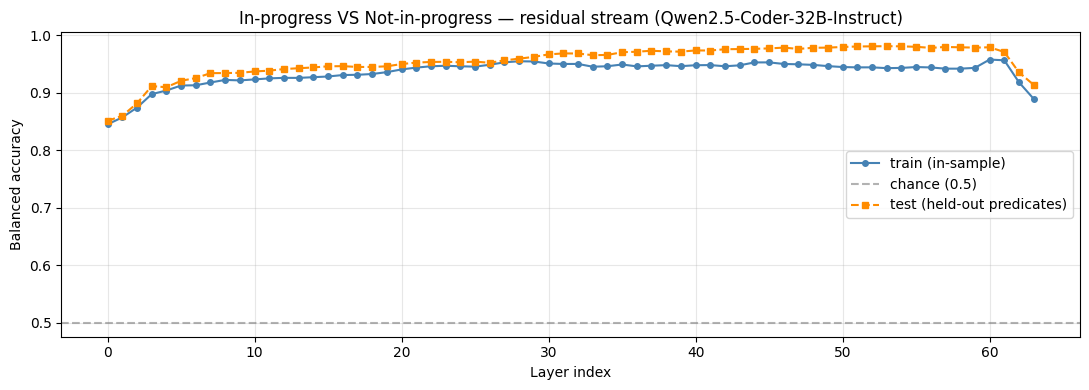

In [178]:
from matplotlib import pyplot as plt

# Visualize balanced accuracy vs layer index (train set probe scores).
plt.rcdefaults()
fig, ax = plt.subplots(figsize=(11, 4))

layers_sorted = sorted(layer_scores)
scores = [layer_scores[l] for l in layers_sorted]

ax.plot(layers_sorted, scores, marker="o", ms=4, color="steelblue", label="train (in-sample)")
ax.axhline(0.5, ls="--", color="gray", alpha=0.6, label="chance (0.5)")

# If test examples exist, overlay held-out scores at all layers
if test_examples:
    test_scores = {}
    for layer in PROBE_LAYERS:
        if layer not in layer_probes:
            continue
        probe = layer_probes[layer]
        probe_device = next(probe.parameters()).device
        Xs, ys = [], []
        for lat, mask, _ in test_examples:
            if layer not in lat.residual:
                continue
            X, y = collect_probe_examples(lat, mask, layer=layer, rep_type=PROBE_REP_TYPE)
            Xs.append(X); ys.append(y)
        if not Xs:
            continue
        X_t = torch.cat(Xs).to(probe_device)
        y_t = torch.cat(ys)
        ba = balanced_accuracy_score(y_t.numpy(), probe.predict(X_t))
        test_scores[layer] = ba
    if test_scores:
        ax.plot(
            sorted(test_scores), [test_scores[l] for l in sorted(test_scores)],
            marker="s", ms=4, color="darkorange", linestyle="--",
            label="test (held-out predicates)",
        )

ax.set_xlabel("Layer index")
ax.set_ylabel("Balanced accuracy")
ax.set_title(f"In-progress VS Not-in-progress — {PROBE_REP_TYPE} stream ({mt.name.split('/')[-1]})")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [180]:
# ── PCA visualization: in-progress vs not-in-progress token representations ───
# For each (sub-sampled) layer, project token activations to 2D via PCA and
# plot in-progress (red) vs not-in-progress (blue) tokens as a scatter.
# Animated across layers following the 03_probe.ipynb pattern.

from sklearn.decomposition import PCA
import matplotlib.animation as animation
from IPython.display import HTML, display

def _gather_layer_reps(examples, layer, rep_type="residual"):
    """Collect Z_pos / Z_neg arrays across all sequences for one layer."""
    Z_pos_parts, Z_neg_parts = [], []
    hidden = None
    for lat, mask, _ in examples:
        X, y = collect_probe_examples(lat, mask, layer=layer, rep_type=rep_type)
        X_np = X.numpy(); y_np = y.numpy()
        hidden = X_np.shape[1]
        if y_np.sum() > 0:
            Z_pos_parts.append(X_np[y_np == 1])
        if (~y_np.astype(bool)).sum() > 0:
            Z_neg_parts.append(X_np[y_np == 0])
    h = hidden or 1
    Z_pos = np.vstack(Z_pos_parts) if Z_pos_parts else np.zeros((0, h))
    Z_neg = np.vstack(Z_neg_parts) if Z_neg_parts else np.zeros((0, h))
    return Z_pos, Z_neg


# Sub-sample layers for the animation (every 4th layer to keep it readable)
viz_layers = PROBE_LAYERS[::4]

# Pre-compute PCA projections per layer
pca_data: dict[int, tuple] = {}
for layer in viz_layers:
    Z_pos, Z_neg = _gather_layer_reps(train_examples, layer, PROBE_REP_TYPE)
    if len(Z_pos) == 0 or len(Z_neg) == 0:
        continue
    rng = np.random.default_rng(42)
    if len(Z_pos) > 2000:
        Z_pos = Z_pos[rng.choice(len(Z_pos), 2000, replace=False)]
    if len(Z_neg) > 2000:
        Z_neg = Z_neg[rng.choice(len(Z_neg), 2000, replace=False)]
    all_z = np.concatenate([Z_pos, Z_neg], axis=0)
    pca = PCA(n_components=2)
    all_2d = pca.fit_transform(all_z)
    pos_2d = all_2d[: len(Z_pos)]
    neg_2d = all_2d[len(Z_pos) :]
    pca_data[layer] = (pos_2d, neg_2d, pca.explained_variance_ratio_)

print(f"PCA computed for {len(pca_data)} layers")

# Fixed axis limits across all layers (so animation doesn't jump)
all_pts = np.concatenate(
    [arr for tup in pca_data.values() for arr in tup[:2]], axis=0
)
x_min, x_max = all_pts[:, 0].min(), all_pts[:, 0].max()
y_min, y_max = all_pts[:, 1].min(), all_pts[:, 1].max()
_pad_x = 0.08 * (x_max - x_min); _pad_y = 0.08 * (y_max - y_min)
x_min -= _pad_x; x_max += _pad_x; y_min -= _pad_y; y_max += _pad_y

# Build animation
fig, ax = plt.subplots(figsize=(7, 6))
_viz_layer_list = sorted(pca_data)

def _update(frame):
    ax.clear()
    layer = _viz_layer_list[frame]
    pos_2d, neg_2d, var_ratio = pca_data[layer]
    ax.scatter(neg_2d[:, 0], neg_2d[:, 1],
               c="firebrick", alpha=0.25, s=8, label=f"not in progress  (n={len(neg_2d)})")
    ax.scatter(pos_2d[:, 0], pos_2d[:, 1],
               c="green", alpha=0.55, s=14, label=f"in progress  (n={len(pos_2d)})")
    ax.set_xlim(x_min, x_max); ax.set_ylim(y_min, y_max)
    ax.set_xlabel(f"PC1 ({var_ratio[0]:.1%} var)")
    ax.set_ylabel(f"PC2 ({var_ratio[1]:.1%} var)")
    ax.set_title(
        f"Clock probe — {PROBE_REP_TYPE} stream   layer {layer}  "
        f"(bal_acc={layer_scores.get(layer, float('nan')):.3f})"
    )
    ax.legend(loc="upper right", markerscale=1.8, fontsize=9)
    ax.grid(alpha=0.3)

ani = animation.FuncAnimation(fig, _update, frames=len(_viz_layer_list), interval=700)
plt.close(fig)  # prevent a blank static figure from appearing
display(HTML(ani.to_jshtml()))  # renders with play/pause/scrub controls

# Uncomment to save as GIF instead:
ani.save("results/clock_pca.gif", writer="pillow", fps=1.5, dpi=120)


PCA computed for 16 layers
2026-04-02 14:14:09 matplotlib.animation INFO     Animation.save using <class 'matplotlib.animation.HTMLWriter'>
2026-04-02 14:14:09 matplotlib.animation DEBUG    frame size in pixels is 700 x 600
2026-04-02 14:14:10 matplotlib.animation DEBUG    MovieWriter: clearing temporary path=<TemporaryDirectory '/tmp/tmpdz8a7lsf'>


2026-04-02 14:14:10 matplotlib.animation INFO     Animation.save using <class 'matplotlib.animation.PillowWriter'>


In [232]:
# ── Stage 1: Augmentation ──────────────────────────────────────────────────────
# Pick one predicate + sample to test the augmentation pipeline interactively.

from src.goals.clock_probe import augment_sample_for_probe

# _DEMO_PRED = "is_palindrome"
# _DEMO_PRED = "is_anagram"
_DEMO_PRED = "is_sorted"

_demo_tp = next(tp for tp in multi_dataset.groups if tp.name == _DEMO_PRED)
_demo_sample = _demo_tp.samples[0]
print(f"P- description: {_demo_sample.p_minus.description if _demo_sample.p_minus else 'No P-'}")

variants = augment_sample_for_probe(_demo_tp, _demo_sample)
print(f"Predicate: {_DEMO_PRED!r}  |  {len(variants)} (sample, prefill) pairs\n")

for aug_s, pf in variants:
    aug_type = aug_s.augmentation[-1]["type"] if aug_s.augmentation else "original"
    print(f"  [{aug_type:<22}]  prefill={repr(pf):<18}  fn={aug_s.function_name}")

print("\nExample augmented code stub (variable_rename, s→text):")
renamed_samples = [(s, pf) for s, pf in variants if s.augmentation and s.augmentation[-1]["type"] == "swap_predicate_order"]
if renamed_samples:
    rich_print(f"[white]{renamed_samples[0][0].code}[/white]")

P- description: check whether len(lst) >= 2
Predicate: 'is_sorted'  |  36 (sample, prefill) pairs

  [original              ]  prefill=''                  fn=is_long_sorted
  [original              ]  prefill='True and '         fn=is_long_sorted
  [original              ]  prefill='False or '         fn=is_long_sorted
  [original              ]  prefill='bool('             fn=is_long_sorted
  [variable_rename       ]  prefill=''                  fn=is_long_sorted
  [variable_rename       ]  prefill='True and '         fn=is_long_sorted
  [variable_rename       ]  prefill='False or '         fn=is_long_sorted
  [variable_rename       ]  prefill='bool('             fn=is_long_sorted
  [variable_rename       ]  prefill=''                  fn=is_long_sorted
  [variable_rename       ]  prefill='True and '         fn=is_long_sorted
  [variable_rename       ]  prefill='False or '         fn=is_long_sorted
  [variable_rename       ]  prefill='bool('             fn=is_long_sorted
  [variable_r

def is_long_sorted(lst: list) -> bool:
    """Return True iff lst is sorted in non-decreasing order and lst has at least 2 elements."""
    return 

In [234]:
# from src.goals.predicate_data import IncompleteCodeSample

# _demo_aug_sample = IncompleteCodeSample(
#     instruction = "Write a python function that takes 3 integers base, power, modulo as input and returns (base ** power) % modulo. Make sure that your function is efficient and can handle large values of power without timing out.",
#     code = 'def mod_exp(base, power, modulo):\n    """',
#     unit_tests = [],
#     function_name = "mod_exp",
#     prefills = [],
#     augmentation= None,
# )

# _demo_aug_sample = IncompleteCodeSample(
#     instruction = "Write a C++ function that takes 3 integers base, power, modulo as input and returns (base ** power) % modulo. Make sure that your function is efficient and can handle large values of power without timing out.",
#     code = 'int mod_exp(int base, int power, int modulo):\n    /*',
#     unit_tests = [],
#     function_name = "mod_exp",
#     prefills = [],
#     augmentation= None,
# )

_demo_prefill = ""

In [235]:
from src.goals.eval import evaluate_single_code
from src.functional import generate_with_patch
from src.goals.data import CodeGenerations, Code
from src.goals.eval import run_evaluation
from src.tokens import prepare_input


_demo_aug_sample, _demo_prefill = variants[10]  # original sample, empty prefill

_demo_prompt = apply_chat_template(
    mt=mt,
    user_query=_demo_aug_sample.instruction.strip(),
    incomplete_code=_demo_aug_sample.code + _demo_prefill,
)



tokenized_prompt = prepare_input(prompts=[_demo_prompt], tokenizer=mt, return_offsets_mapping=True)
offsets = tokenized_prompt.pop("offset_mapping")[0]

gen_ids = mt._model.generate(
    input_ids=tokenized_prompt.input_ids.to(mt.device),
    attention_mask=tokenized_prompt.attention_mask.to(mt.device),
    max_new_tokens=MAX_GEN_TOKENS,
    do_sample=False,
)[0][tokenized_prompt.input_ids.shape[1] :]

lm_completion = mt.tokenizer.decode(gen_ids, skip_special_tokens=False)

rich_print(
    f'"[white]{_demo_prompt}[/white][bright_yellow]{lm_completion}[/bright_yellow]"'
)


code_stop_tag: str | None = "</code>"
if code_stop_tag:
    cur_stop_tag = code_stop_tag if code_stop_tag in lm_completion else "\n"
    lm_completion = lm_completion.split(cur_stop_tag)[0].strip()

incomplete_prefix = _demo_aug_sample.code + _demo_prefill
if incomplete_prefix.endswith(" ") is False:
    incomplete_prefix += " "
full_code = incomplete_prefix + lm_completion
rich_print(f"[white]{full_code}[/white]")

eval = evaluate_single_code(
    full_code = full_code,
    unit_tests = _demo_aug_sample.unit_tests,
    function_name = _demo_aug_sample.function_name,
)
rich_print(eval)


_demo_lat = cache_latents_for_sequence(
    mt=mt,
    prompt_ids=tokenized_prompt.input_ids[0].tolist(),
    gen_ids=gen_ids.tolist(),
    layers=list(layer_probes.keys()),
    include_mlp=True,
    include_attn=True,
)

"<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python function that returns True iff the list has at least 2 elements and is sorted in non-decreasing 
order.<|im_end|>
<|im_start|>assistant
<code>
def is_long_sorted(elements: list) -> bool:
    """Return True iff elements has at least 2 elements and is sorted in non-decreasing order."""
    return False or 2 <= len(elements) and all(elements <= elements for i in range(len(elements) - 1))
</code>

This function first checks if the length of the list `elements` is at least 2. If it is, it then checks if every 
element in the list is less than or equal to the next element, ensuring the list is sorted in non-decreasing order.
If both conditions are satisfied, the function returns `True`; otherwise, it returns `False`.<|im_end|>"

def is_long_sorted(elements: list) -> bool:
    """Return True iff elements has at least 2 elements and is sorted in non-decreasing order."""
    return False or 2 <= len(elements) and all(elements <= elements for i in range(len(elements) - 1))

SingleCodeEval(
    code='def is_long_sorted(elements: list) -> bool:\n    """Return True iff elements has at least 2 elements and 
is sorted in non-decreasing order."""\n    return False or 2 <= len(elements) and all(elements[i] <= elements[i + 
1] for i in range(len(elements) - 1))',
    verdict='PASSED',
    unit_test_results=[
        UnitTestResult(input=[1, 2, 3], expected=True, actual='True', passed=True, error=None),
        UnitTestResult(input=[3, 2, 1], expected=False, actual='False', passed=True, error=None),
        UnitTestResult(input=[1], expected=False, actual='False', passed=True, error=None),
        UnitTestResult(input=[], expected=False, actual='False', passed=True, error=None),
        UnitTestResult(input=[1, 1, 2], expected=True, actual='True', passed=True, error=None),
        UnitTestResult(input=[2, 1], expected=False, actual='False', passed=True, error=None),
        UnitTestResult(input=[5, 5], expected=True, actual='True', passed=True, error=None),
        UnitTestResult(input=[-1, 0, 1], expected=True, actual='True', passed=True, error=None),
        UnitTestResult(input=[0, 0], expected=True, actual='True', passed=True, error=None)
    ],
    warnings=[],
    error_message=None,
    prefill=None,
    output=''
)

In [236]:
print("SequenceLatents:")
print(f"  prompt_len:  {_demo_lat.prompt_len}")
print(f"  gen_ids:     {len(_demo_lat.gen_ids)} tokens")
print(
    f"  residual:    {len(_demo_lat.residual)} layers, each shape {next(iter(_demo_lat.residual.values())).shape}"
)
print(f"  mlp:         {len(_demo_lat.mlp)} layers")
print(f"  attn:        {len(_demo_lat.attn)} layers")

# anchor_patterns = list(set(anchor_patterns))  # deduplicate
_demo_masks = find_in_progress_mask_oracle(
    latents=_demo_lat,
    p_plus_description=_demo_tp.p_plus.description,
    p_minus_description=_demo_aug_sample.p_minus.description,
    tokenizer=mt.tokenizer,
    prefill=_demo_prefill,
)
_demo_mask = torch.stack([torch.tensor(mask) for mask in _demo_masks], dim=0).any(
    dim=0
)  # (seq_len,) bool tensor indicating in-progress tokens

print(
    f"\nin_progress_mask: {_demo_mask.sum()}/{len(_demo_mask)} tokens labeled in-progress"
)
gen_toks = [mt.tokenizer.decode(tok) for tok in _demo_lat.gen_ids]
formatted_gen = ""
for i, (tok, lbl) in enumerate(zip(gen_toks, _demo_mask)):
    formatted_tok = (
        f"[bright_green]{tok}[/bright_green]" if lbl else f"[white]{tok}[/white]"
    )
    formatted_gen += formatted_tok
rich_print(formatted_gen)

SequenceLatents:
  prompt_len:  114
  gen_ids:     104 tokens
  residual:    64 layers, each shape torch.Size([104, 5120])
  mlp:         64 layers
  attn:        64 layers
2026-04-02 14:39:24 httpx DEBUG    load_ssl_context verify=True cert=None trust_env=True http2=False
2026-04-02 14:39:24 httpx DEBUG    load_verify_locations cafile='/disk/u/arnab/miniconda3/envs/goals/lib/python3.11/site-packages/certifi/cacert.pem'


2026-04-02 14:39:24 anthropic._base_client DEBUG    Request options: {'method': 'post', 'url': '/v1/messages', 'timeout': Timeout(connect=5.0, read=600, write=600, pool=600), 'files': None, 'idempotency_key': 'stainless-python-retry-c6fa2b2f-53e2-4392-bff6-5537d16eb7da', 'content': None, 'json_data': {'max_tokens': 1024, 'messages': [{'role': 'user', 'content': [{'type': 'text', 'text': 'You are a code analysis assistant. A language model generated the following code:\nNote: generation was prefixed with "False or ".\n\n<generated_code>\n2 <= len(elements) and all(elements[i] <= elements[i + 1] for i in range(len(elements) - 1))\n</code>\n\nThis function first checks if the length of the list `elements` is at least 2. If it is, it then checks if every element in the list is less than or equal to the next element, ensuring the list is sorted in non-decreasing order. If both conditions are satisfied, the function returns `True`; otherwise, it returns `False`.\n</generated_code>\n\nThe fun

2 <= len(elements) and all(elements[i] <= elements[i + 1] for i in range(len(elements) - 1))
</code>

This function first checks if the length of the list `elements` is at least 2. If it is, it then checks if every 
element in the list is less than or equal to the next element, ensuring the list is sorted in non-decreasing order.
If both conditions are satisfied, the function returns `True`; otherwise, it returns `False`.<|im_end|>

In [237]:
_demo_lat.code_start, len(_demo_lat.prompt_ids)

(73, 114)

In [238]:
code_segment = "".join(mt.tokenizer.decode(token_id) for token_id in _demo_lat.prompt_ids[_demo_lat.code_start :])
print(len(_demo_lat.prompt_ids[_demo_lat.code_start :]))
rich_print(f"[white]{code_segment}[/white]")

41


<code>
def is_long_sorted(elements: list) -> bool:
    """Return True iff elements has at least 2 elements and is sorted in non-decreasing order."""
    return False or 

In [239]:
LAYER_IDX = 47

# Xs, ys = collect_probe_examples(
#     _demo_lat, _demo_mask.cpu().numpy(), layer=layer_idx, rep_type=PROBE_REP_TYPE
# )

Xs = torch.concat([_demo_lat.code_residual[LAYER_IDX], _demo_lat.residual[LAYER_IDX]], dim=0)
Xs.shape, _demo_lat.residual[LAYER_IDX].shape, len(_demo_lat.prompt_ids[_demo_lat.code_start : ]), len(_demo_lat.gen_ids)

(torch.Size([145, 5120]), torch.Size([104, 5120]), 41, 104)

In [240]:
probe = layer_probes[layer_idx]
probe_device = next(probe.parameters()).device
preds = probe.predict(Xs.to(probe_device))
print(preds.shape)
preds

(145,)


array([0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0,
       1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

In [241]:
# # probe.linear.weight @ Xs[0].to(probe_device)
# from torch.nn.functional import cosine_similarity

# h = Xs[5].to(probe_device)

# (
#     cosine_similarity(
#         probe.linear.weight[1].unsqueeze(0), h.unsqueeze(0), dim=1
#     ),
#     cosine_similarity(
#         probe.linear.weight[0].unsqueeze(0), h.unsqueeze(0), dim=1
#     ),
# )

# cosine_similarity(
#     probe.linear.weight[1].unsqueeze(0), probe.linear.weight[0].unsqueeze(0), dim=1
# )

# in_progress_dir =  probe.linear.weight[1] # - probe.linear.weight[0]
# cosine_similarity(in_progress_dir.unsqueeze(0), h.unsqueeze(0), dim=1)

In [242]:
from src.attention import _safe_token
from circuitsvis.tokens import colored_tokens
from IPython.display import display
from torch.nn.functional import cosine_similarity

in_progress_dir = probe.linear.weight[1]  # - probe.linear.weight[0]
scores = []

for i in range(len(Xs)):
    h = Xs[i].to(probe_device)
    score = cosine_similarity(
        in_progress_dir.unsqueeze(0), h.unsqueeze(0), dim=1
    ).item()
    scores.append(score)

tokens = [
    _safe_token(mt.tokenizer.decode(tok))
    # for tok in _demo_lat.gen_ids
    for tok in _demo_lat.prompt_ids[_demo_lat.code_start :] + _demo_lat.gen_ids
]

print(_demo_prompt)
display(
    colored_tokens(
        tokens, scores, positive_color="seagreen", negative_color="firebrick"
    )
)

<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python function that returns True iff the list has at least 2 elements and is sorted in non-decreasing order.<|im_end|>
<|im_start|>assistant
<code>
def is_long_sorted(elements: list) -> bool:
    """Return True iff elements has at least 2 elements and is sorted in non-decreasing order."""
    return False or 


In [79]:
for li in range(0, mt.n_layer, 2):
    # _cur_direction = layer_probes[li].linear.weight[1] - layer_probes[li].linear.weight[0]
    _cur_direction = layer_probes[li].linear.weight[1]
    # _cur_direction = layer_probes[li].linear.weight[0]
    _cur_direction = _cur_direction.to(mt.dtype).to(mt.device)
    ll_pred = logit_lens(mt=mt, h=_cur_direction, k=15)
    ll_msg = [str(pred.token) for pred in ll_pred]
    print(f"Layer {li}: logit lens = {ll_msg}")

Layer 0: logit lens = ['arta', '@student', '甸', 'zsche', 'asz', '合法性', 'ational', 'ghi', '(pad', '亡', ' refr', 'anh', '<quote', '雷斯', '国资']
Layer 2: logit lens = ['<|fim_suffix|>', '在床上', '保驾', 'emacs', '瞒', 'ToDevice', ' None', '(None', 'ipes', '-European', '\\_', ' diminish', '耳', '例', 'anh']
Layer 4: logit lens = ['<|fim_suffix|>', '碍', '/or', '\\', '\\_', '保驾', 'hood', ' (', '(', '-', ' diminish', '缘', ',', '_LSB', ' it']
Layer 6: logit lens = ['<|fim_suffix|>', '/or', '\\', ' x', ' (', '\\_', ' n', '(', ' _', '保驾', ' NUIT', ' it', '碍', '影', '-']
Layer 8: logit lens = ['<|fim_suffix|>', '/or', '\\', ' (', ' x', ' it', '-', '骗取', '分期', '其所', ' [', '瞒', ' *', '无力', ' n']
Layer 10: logit lens = [' (', '<|fim_suffix|>', '/or', '拒不', '\\', ' [', '乱象', '⏤', ' x', '无力', '禁忌', '风波', ' ', ' Out', 'Margins']
Layer 12: logit lens = [' (', '/or', '<|fim_suffix|>', '⏤', '-', ' [', ' NUIT', '\\', '\\_', '(', ' ', '"', ' smelled', ' r', ' *']
Layer 14: logit lens = [' (', '⏤', '/or', ' NUIT', 'TR

## Regression Probe — Progress Signal (`c`)

In [16]:
from src.goals.clock_probe import (
    collect_regression_examples,
    LinearRegressionProbe,
    train_regression_probe,
    eval_regression_probe,
)


In [17]:
# Collect (X, y) regression examples per layer across all train records.
# y values: 1.0 at first token of each in-progress span → 0.0 at last;
# background tokens sampled at rate 0.5× span length, labeled 0.0.

from tqdm.auto import tqdm

reg_rng = np.random.default_rng(42)

reg_layer_data: dict[int, tuple] = {}  # layer → (X, y)
for layer in tqdm(PROBE_LAYERS):
    Xs, ys = [], []
    for r in train_records:
        if layer not in r.latents.residual:
            continue
        X, y = collect_regression_examples(
            r.latents, r.p_plus_mask, r.p_minus_mask,
            layer=layer, rep_type=PROBE_REP_TYPE, rng=reg_rng,
        )
        if len(X) > 0:
            Xs.append(X); ys.append(y)
    if Xs:
        reg_layer_data[layer] = (torch.cat(Xs), torch.cat(ys))

X0, y0 = reg_layer_data[PROBE_LAYERS[0]]
print(f'Collected data for {len(reg_layer_data)} layers')
print(f'Example — layer {PROBE_LAYERS[0]}: {X0.shape[0]} examples  '
      f'(pos: {(y0 > 0).sum().item()}  bg: {(y0 == 0).sum().item()})')


  0%|          | 0/64 [00:00<?, ?it/s]

Collected data for 64 layers
Example — layer 0: 13369 examples  (pos: 8993  bg: 4376)


In [18]:
# Train a LinearRegressionProbe per layer; record R² on the train set.
# (In-sample R² first — generalization tested in the next cell.)

reg_layer_scores: dict[int, float] = {}
reg_layer_probes: dict[int, LinearRegressionProbe] = {}

for layer, (X_all, y_all) in reg_layer_data.items():
    probe = train_regression_probe(X_all, y_all)
    result = eval_regression_probe(probe, X_all, y_all)
    reg_layer_scores[layer] = result['r2']
    reg_layer_probes[layer] = probe
    print(f'  Layer {layer:3d}: R²={result["r2"]:+.3f}  '
          f'MAE={result["mae"]:.3f}  MSE={result["mse"]:.4f}')

best_reg_layer = max(reg_layer_scores, key=reg_layer_scores.get)
print(f'\nBest layer: {best_reg_layer}  (R²={reg_layer_scores[best_reg_layer]:+.3f})')


  Layer   0: R²=+0.800  MAE=0.113  MSE=0.0245
  Layer   1: R²=+0.820  MAE=0.106  MSE=0.0220
  Layer   2: R²=+0.844  MAE=0.097  MSE=0.0191
  Layer   3: R²=+0.876  MAE=0.085  MSE=0.0152
  Layer   4: R²=+0.884  MAE=0.080  MSE=0.0141
  Layer   5: R²=+0.893  MAE=0.077  MSE=0.0131
  Layer   6: R²=+0.897  MAE=0.074  MSE=0.0126
  Layer   7: R²=+0.897  MAE=0.074  MSE=0.0126
  Layer   8: R²=+0.896  MAE=0.074  MSE=0.0127
  Layer   9: R²=+0.896  MAE=0.074  MSE=0.0127
  Layer  10: R²=+0.897  MAE=0.074  MSE=0.0126
  Layer  11: R²=+0.899  MAE=0.073  MSE=0.0123
  Layer  12: R²=+0.906  MAE=0.069  MSE=0.0115
  Layer  13: R²=+0.911  MAE=0.067  MSE=0.0109
  Layer  14: R²=+0.912  MAE=0.066  MSE=0.0107
  Layer  15: R²=+0.917  MAE=0.064  MSE=0.0102
  Layer  16: R²=+0.924  MAE=0.061  MSE=0.0093
  Layer  17: R²=+0.925  MAE=0.060  MSE=0.0091
  Layer  18: R²=+0.924  MAE=0.060  MSE=0.0093
  Layer  19: R²=+0.929  MAE=0.058  MSE=0.0087
  Layer  20: R²=+0.929  MAE=0.057  MSE=0.0087
  Layer  21: R²=+0.932  MAE=0.056 

In [19]:
# Generalization: evaluate on held-out test records (no retraining).

if not test_records:
    print("No test records loaded.")
else:
    reg_test_layer_scores: dict[int, float] = {}
    for layer, probe in reg_layer_probes.items():
        Xs, ys = [], []
        for r in test_records:
            if layer not in r.latents.residual:
                continue
            X, y = collect_regression_examples(
                r.latents,
                r.p_plus_mask,
                r.p_minus_mask,
                layer=layer,
                rep_type=PROBE_REP_TYPE,
                rng=np.random.default_rng(0),
            )
            if len(X) > 0:
                Xs.append(X)
                ys.append(y)
        if not Xs:
            continue
        result = eval_regression_probe(probe, torch.cat(Xs), torch.cat(ys))
        reg_test_layer_scores[layer] = result["r2"]

    # Report best-layer result
    if best_reg_layer in reg_test_layer_scores:
        print(
            f"Layer {best_reg_layer} (best train) — test R²: "
            f"{reg_test_layer_scores[best_reg_layer]:+.3f}"
        )


Layer 49 (best train) — test R²: +0.647


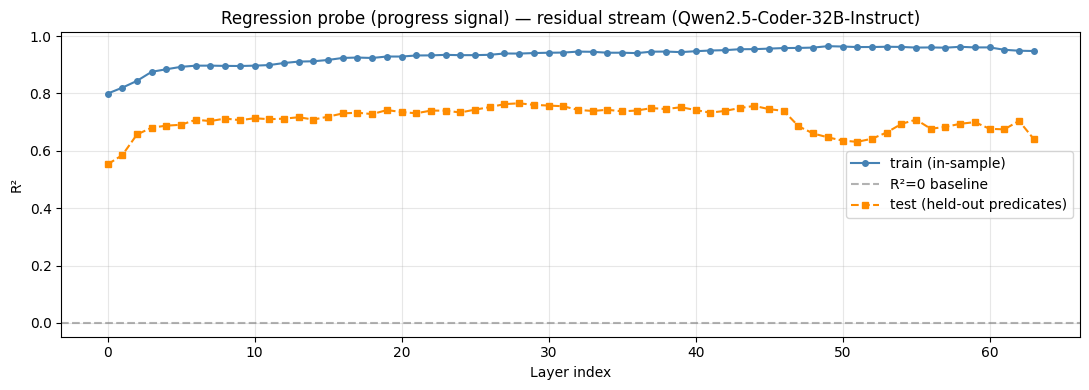

In [21]:
from matplotlib import pyplot as plt

# ── R² vs layer index ──────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(11, 4))

layers_sorted = sorted(reg_layer_scores)
ax.plot(layers_sorted, [reg_layer_scores[l] for l in layers_sorted],
        marker='o', ms=4, color='steelblue', label='train (in-sample)')
ax.axhline(0.0, ls='--', color='gray', alpha=0.6, label='R²=0 baseline')

if test_records and reg_test_layer_scores:
    t_layers = sorted(reg_test_layer_scores)
    ax.plot(t_layers, [reg_test_layer_scores[l] for l in t_layers],
            marker='s', ms=4, color='darkorange', linestyle='--',
            label='test (held-out predicates)')

ax.set_xlabel('Layer index')
ax.set_ylabel('R²')
ax.set_title(f'Regression probe (progress signal) — {PROBE_REP_TYPE} stream '
             f'({mt.name.split("/")[-1]})')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()


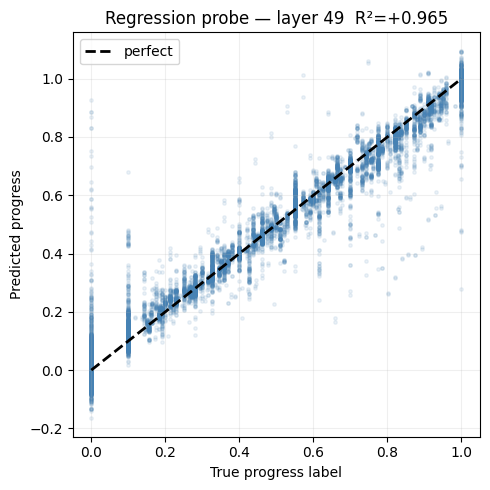

In [22]:
# ── Predicted vs true progress — best layer, train set ────────────────────
probe = reg_layer_probes[best_reg_layer]
X_best, y_best = reg_layer_data[best_reg_layer]
y_pred = probe.predict(X_best)

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(y_best.numpy(), y_pred, alpha=0.1, s=6, color="steelblue")
ax.plot([0, 1], [0, 1], "k--", lw=2, label="perfect")
ax.set_xlabel("True progress label")
ax.set_ylabel("Predicted progress")
ax.set_title(
    f"Regression probe — layer {best_reg_layer}  "
    f"R²={reg_layer_scores[best_reg_layer]:+.3f}"
)
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()


In [23]:
from src.functional import logit_lens

for li in range(0, mt.n_layer, 2):
    # _cur_direction = layer_probes[li].linear.weight[1] - layer_probes[li].linear.weight[0]
    _cur_direction = reg_layer_probes[li].linear.weight.squeeze()
    # _cur_direction = layer_probes[li].linear.weight[0]
    _cur_direction = _cur_direction.to(mt.dtype).to(mt.device)
    ll_pred = logit_lens(mt=mt, h=_cur_direction, k=15)
    ll_msg = [str(pred.token) for pred in ll_pred]
    print(f"Layer {li}: logit lens = {ll_msg}")

Layer 0: logit lens = [' Sands', ' Giuliani', ' dri', ' *----------------------------------------------------------------', '衮', 'short', '__(*', ' точно', ' nackte', '杭', '/fw', 'ければ', ' Тем', '/Runtime', 'studio']
Layer 2: logit lens = ['稼', ' Giuliani', '적', 'ULT', '(states', 'altet', ' sequ', 'bris', 'hold', 'DOB', 'etal', ' Greene', ' Calder', '否', 'leness']
Layer 4: logit lens = ['.communic', ' kra', 'leness', '.TextInput', ' Bes', '历代', '/Runtime', 'fleet', 'ela', 'EGIN', 'Seg', ' flo', '.Dir', ' VIN', 'Bes']
Layer 6: logit lens = [' Thi', '泡', ' Hou', '作出', '.Compose', 'NSError', ' точно', 'ayed', ' mig', '_NOP', 'reta', ' Aug', ' iframe', ' Breaking', 'IF']
Layer 8: logit lens = ['屎', '厕', '寓', ' точно', '_bm', 'hil', 'ayed', ' Bir', ' Aug', '_NOP', '一笔', 'CONDS', 'csi', ' assorted', ' nach']
Layer 10: logit lens = [' Bir', 'tent', 'ayed', 'reeNode', '沟', ' prox', ' =~', ' Lite', ':UIControl', 'ё', '季', 'ula', '泛', ' Rud', '砼']
Layer 12: logit lens = ['界', ' Lite', 'uli', '泡',

In [33]:
# ── Stage 1: Augmentation ──────────────────────────────────────────────────────
# Pick one predicate + sample to test the augmentation pipeline interactively.

from src.goals.clock_probe import augment_sample_for_probe

# _DEMO_PRED = "is_palindrome"
# _DEMO_PRED = "is_anagram"
# _DEMO_PRED = "is_sorted"
# _DEMO_PRED = "has_unique_elements"
_DEMO_PRED = "is_perfect_square"

_demo_tp = next(tp for tp in multi_dataset.groups if tp.name == _DEMO_PRED)
_demo_sample = _demo_tp.samples[2]
print(f"P- description: {_demo_sample.p_minus.description if _demo_sample.p_minus else 'No P-'}")

variants = augment_sample_for_probe(_demo_tp, _demo_sample)
print(f"Predicate: {_DEMO_PRED!r}  |  {len(variants)} (sample, prefill) pairs\n")

for aug_s, pf in variants:
    aug_type = aug_s.augmentation[-1]["type"] if aug_s.augmentation else "original"
    print(f"  [{aug_type:<22}]  prefill={repr(pf):<18}  fn={aug_s.function_name}")

print("\nExample augmented code stub (variable_rename, s→text):")
renamed_samples = [(s, pf) for s, pf in variants if s.augmentation and s.augmentation[-1]["type"] == "swap_predicate_order"]
if renamed_samples:
    rich_print(f"[white]{renamed_samples[0][0].code}[/white]")

P- description: check whether n % 2 == 0
Predicate: 'is_perfect_square'  |  36 (sample, prefill) pairs

  [original              ]  prefill=''                  fn=is_even_perfect_square
  [original              ]  prefill='True and '         fn=is_even_perfect_square
  [original              ]  prefill='False or '         fn=is_even_perfect_square
  [original              ]  prefill='bool('             fn=is_even_perfect_square
  [variable_rename       ]  prefill=''                  fn=is_even_perfect_square
  [variable_rename       ]  prefill='True and '         fn=is_even_perfect_square
  [variable_rename       ]  prefill='False or '         fn=is_even_perfect_square
  [variable_rename       ]  prefill='bool('             fn=is_even_perfect_square
  [variable_rename       ]  prefill=''                  fn=is_even_perfect_square
  [variable_rename       ]  prefill='True and '         fn=is_even_perfect_square
  [variable_rename       ]  prefill='False or '         fn=is_even_perfect_s

def is_even_perfect_square(n: int) -> bool:
    """Return True iff n is a perfect square and n is a non-negative even integer."""
    return 

In [56]:
from src.goals.predicate_data import IncompleteCodeSample

# _demo_aug_sample = IncompleteCodeSample(
#     instruction = "Write a python function that takes 3 integers base, power, modulo as input and returns (base ** power) % modulo. Make sure that your function is efficient and can handle large values of power without timing out.",
#     code = 'def mod_exp(base, power, modulo):\n    """',
#     unit_tests = [],
#     function_name = "mod_exp",
#     prefills = [],
#     augmentation= None,
# )

_demo_aug_sample = IncompleteCodeSample(
    instruction = "Write a C++ function that takes 3 integers base, power, modulo as input and returns (base ** power) % modulo. Make sure that your function is efficient and can handle large values of power without timing out.",
    code = 'int mod_exp(int base, int power, int modulo):\n    /*',
    unit_tests = [],
    function_name = "mod_exp",
    prefills = [],
    augmentation= None,
)

_demo_prefill = ""

In [57]:
from src.goals.eval import evaluate_single_code
from src.functional import generate_with_patch
from src.goals.data import CodeGenerations, Code
from src.goals.eval import run_evaluation
from src.tokens import prepare_input


# _demo_aug_sample, _demo_prefill = variants[0]  # original sample, empty prefill

_demo_prompt = apply_chat_template(
    mt=mt,
    user_query=_demo_aug_sample.instruction.strip(),
    incomplete_code=_demo_aug_sample.code + _demo_prefill,
)



tokenized_prompt = prepare_input(prompts=[_demo_prompt], tokenizer=mt, return_offsets_mapping=True)
offsets = tokenized_prompt.pop("offset_mapping")[0]

gen_ids = mt._model.generate(
    input_ids=tokenized_prompt.input_ids.to(mt.device),
    attention_mask=tokenized_prompt.attention_mask.to(mt.device),
    # max_new_tokens=MAX_GEN_TOKENS,
    max_new_tokens=256,
    do_sample=False,
)[0][tokenized_prompt.input_ids.shape[1] :]

lm_completion = mt.tokenizer.decode(gen_ids, skip_special_tokens=False)

rich_print(
    f'"[white]{_demo_prompt}[/white][bright_yellow]{lm_completion}[/bright_yellow]"'
)


code_stop_tag: str | None = "</code>"
if code_stop_tag:
    cur_stop_tag = code_stop_tag if code_stop_tag in lm_completion else "\n"
    lm_completion = lm_completion.split(cur_stop_tag)[0].strip()

incomplete_prefix = _demo_aug_sample.code + _demo_prefill
if incomplete_prefix.endswith(" ") is False:
    incomplete_prefix += " "
full_code = incomplete_prefix + lm_completion
rich_print(f"[white]{full_code}[/white]")

eval = evaluate_single_code(
    full_code = full_code,
    unit_tests = _demo_aug_sample.unit_tests,
    function_name = _demo_aug_sample.function_name,
)
rich_print(eval)


_demo_lat = cache_latents_for_sequence(
    mt=mt,
    prompt_ids=tokenized_prompt.input_ids[0].tolist(),
    gen_ids=gen_ids.tolist(),
    layers=list(reg_layer_probes.keys()),
    include_mlp=True,
    include_attn=True,
)

"<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a C++ function that takes 3 integers base, power, modulo as input and returns (base ** power) % modulo. Make 
sure that your function is efficient and can handle large values of power without timing out.<|im_end|>
<|im_start|>assistant
<code>
int mod_exp(int base, int power, int modulo):
    /* This function calculates (base^power) % modulo using the method of exponentiation by squaring.
       It is efficient and works well even for large powers. */
    
    if (modulo == 1) return 0; // In case modulo is 1, the result is always 0.
    
    long long result = 1;
    long long base_mod = base % modulo; // Work with base % modulo to keep numbers small
    
    while (power > 0) {
        // If power is odd, multiply base with result
        if (power % 2 == 1) {
            result = (result * base_mod) % modulo;
        }
        // Now power must be even, so we square the base
        base_mod = (base_mod * base_mod) % modulo;
        power /= 2; // Divide power by 2
    }
    
    return static_cast<int>(result);
}
</code>

Note: The function uses `long long` to handle intermediate results that might overflow when using `int`. The final 
result is cast back to `int` before returning, assuming that the final result will fit within the range of an 
`int`. If the result could potentially exceed this range, you may want to"

int mod_exp(int base, int power, int modulo):
    /* This function calculates (base^power) % modulo using the method of exponentiation by squaring.
       It is efficient and works well even for large powers. */
    
    if (modulo == 1) return 0; // In case modulo is 1, the result is always 0.
    
    long long result = 1;
    long long base_mod = base % modulo; // Work with base % modulo to keep numbers small
    
    while (power > 0) {
        // If power is odd, multiply base with result
        if (power % 2 == 1) {
            result = (result * base_mod) % modulo;
        }
        // Now power must be even, so we square the base
        base_mod = (base_mod * base_mod) % modulo;
        power /= 2; // Divide power by 2
    }
    
    return static_cast<int>(result);
}

SingleCodeEval(
    code='int mod_exp(int base, int power, int modulo):\n    /* This function calculates (base^power) % modulo 
using the method of exponentiation by squaring.\n       It is efficient and works well even for large powers. */\n 
\n    if (modulo == 1) return 0; // In case modulo is 1, the result is always 0.\n    \n    long long result = 1;\n
long long base_mod = base % modulo; // Work with base % modulo to keep numbers small\n    \n    while (power > 0) 
{\n        // If power is odd, multiply base with result\n        if (power % 2 == 1) {\n            result = 
(result * base_mod) % modulo;\n        }\n        // Now power must be even, so we square the base\n        
base_mod = (base_mod * base_mod) % modulo;\n        power /= 2; // Divide power by 2\n    }\n    \n    return 
static_cast<int>(result);\n}',
    verdict='SYNTAX_ERROR',
    unit_test_results=[],
    warnings=[],
    error_message="unmatched '}' (<string>, line 21)",
    prefill=None,
    output=''
)

In [58]:
_demo_lat.code_start, len(_demo_lat.prompt_ids), len(_demo_lat.gen_ids)

(93, 111, 256)

In [59]:
print("SequenceLatents:")
print(f"  prompt_len:  {_demo_lat.prompt_len}")
print(f"  gen_ids:     {len(_demo_lat.gen_ids)} tokens")
print(
    f"  residual:    {len(_demo_lat.residual)} layers, each shape {next(iter(_demo_lat.residual.values())).shape}"
)
print(f"  mlp:         {len(_demo_lat.mlp)} layers")
print(f"  attn:        {len(_demo_lat.attn)} layers")

# anchor_patterns = list(set(anchor_patterns))  # deduplicate
_demo_masks = find_in_progress_mask_oracle(
    latents=_demo_lat,
    p_plus_description=_demo_tp.p_plus.description,
    p_minus_description=_demo_aug_sample.p_minus.description,
    tokenizer=mt.tokenizer,
    prefill=_demo_prefill,
)
_demo_mask = torch.stack([torch.tensor(mask) for mask in _demo_masks], dim=0).any(
    dim=0
)  # (seq_len,) bool tensor indicating in-progress tokens

print(
    f"\nin_progress_mask: {_demo_mask.sum()}/{len(_demo_mask)} tokens labeled in-progress"
)
gen_toks = [mt.tokenizer.decode(tok) for tok in _demo_lat.gen_ids]
formatted_gen = ""
for i, (tok, lbl) in enumerate(zip(gen_toks, _demo_mask)):
    formatted_tok = (
        f"[bright_green]{tok}[/bright_green]" if lbl else f"[white]{tok}[/white]"
    )
    formatted_gen += formatted_tok
rich_print(formatted_gen)

SequenceLatents:
  prompt_len:  111
  gen_ids:     256 tokens
  residual:    64 layers, each shape torch.Size([256, 5120])
  mlp:         64 layers
  attn:        64 layers


AttributeError: 'IncompleteCodeSample' object has no attribute 'p_minus'

In [60]:
LAYER_IDX = 47

# Xs, ys = collect_probe_examples(
#     _demo_lat, _demo_mask.cpu().numpy(), layer=layer_idx, rep_type=PROBE_REP_TYPE
# )

Xs = torch.concat(
    [_demo_lat.code_residual[LAYER_IDX], _demo_lat.residual[LAYER_IDX]], dim=0
)
(
    Xs.shape,
    _demo_lat.residual[LAYER_IDX].shape,
    len(_demo_lat.prompt_ids[_demo_lat.code_start :]),
    len(_demo_lat.gen_ids),
)

(torch.Size([274, 5120]), torch.Size([256, 5120]), 18, 256)

In [61]:
from src.attention import _safe_token
from circuitsvis.tokens import colored_tokens
from IPython.display import display
from torch.nn.functional import cosine_similarity

scores = []
reg_probe = reg_layer_probes[LAYER_IDX]
reg_probe_device = next(reg_probe.parameters()).device

for i in range(len(Xs)):
    h = Xs[i].to(reg_probe_device)
    score = reg_probe(h.unsqueeze(0)).item()
    scores.append(score)

tokens = [
    _safe_token(mt.tokenizer.decode(tok))
    # for tok in _demo_lat.gen_ids
    for tok in _demo_lat.prompt_ids[_demo_lat.code_start :] + _demo_lat.gen_ids
]

print(_demo_prompt)
display(
    colored_tokens(
        tokens, scores, positive_color="seagreen", negative_color="firebrick"
    )
)

<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a C++ function that takes 3 integers base, power, modulo as input and returns (base ** power) % modulo. Make sure that your function is efficient and can handle large values of power without timing out.<|im_end|>
<|im_start|>assistant
<code>
int mod_exp(int base, int power, int modulo):
    /*


In [ ]:
""